# Fisher e DALI
## A persistência da não gaussianidade

**Igor Stellet · Estatística Bayesiana · Doutorado no CBPF · 2026/2**

**Tema:** Higher-order Fisher Matrix (DALI).

Este será o notebook principal do projeto, contendo todas as hipóteses, deduções, exxemplos, aplicações e discussções dos resultados. As funções principais e que acredito que serão úteis para outros projetos serão acrescentadas em `src/dali.py`.

O planejamento está no [README](README.md).

O título *A persistência da não gaussianidade*  é inspirada na obra *A Persistência da Memória*, de Salvador Dalí (1931), [registrada no MoMA](https://www.moma.org/collection/works/79018). Ao final do projeto, farei uma oficina visual, presente no Bloco 7, para ilustrar a obra e o motivo do artista da nome ao método :), utilizando uma construção matemática própria.

# 0. Leitura e execução

O percurso de cada seção será: **pergunta → modelo e hipóteses → dedução → implementação → verificação → interpretação**.

1. Abra este arquivo com o kernel **Análise Bayesiana (.venv)** do repositório.
2. Execute a configuração abaixo, a partir da raiz do repositório ou da pasta `projeto/`.
3. Nas próximas versões, as análises serão acrescentadas na ordem do sumário e os parâmetros de execução serão documentados nos próprios blocos.

O único código científico executado para esta entrega é a figura de orientação do README, cujo script acompanha os arquivos. O módulo principal está preparado para receber as funções; ainda não implementa as aproximações.


In [1]:
from pathlib import Path
import sys

# Aceita iniciar o kernel na raiz do repositório ou na pasta deste notebook.
candidatos = (Path.cwd(), Path.cwd() / "projeto")
PROJETO_DIR = next(
    (pasta.resolve() for pasta in candidatos if (pasta / "src" / "dali.py").is_file()),
    None,
)
if PROJETO_DIR is None:
    raise FileNotFoundError(
        "Abra o notebook na pasta projeto/ ou na raiz do repositório, "
        "mantendo src/dali.py junto dos arquivos do projeto."
    )

if str(PROJETO_DIR) not in sys.path:
    sys.path.insert(0, str(PROJETO_DIR))

from src import dali

FIGURAS_DIR = PROJETO_DIR / "figuras"
DADOS_DIR = PROJETO_DIR / "data"
TABELAS_DIR = PROJETO_DIR / "tabelas"
SEMENTE = 2026

print("Pasta do projeto localizada:", PROJETO_DIR.name)
print("Módulo local carregado:", dali.__name__)
print("Estrutura inicial pronta; análises científicas a desenvolver.")


Pasta do projeto localizada: projeto
Módulo local carregado: src.dali
Estrutura inicial pronta; análises científicas a desenvolver.


## Sumário

- [1. Modelo probabilístico e Fisher](#bloco-1)
- [2. Hierarquia de DALI](#bloco-2)
- [3. Exemplos controlados](#bloco-3)
- [4. Aplicação à Lista 3](#bloco-4)
- [5. Supernovas](#bloco-5)
- [6. BAO e combinação de observáveis](#bloco-6)
- [7. Oficina visual inspirada em Dalí](#bloco-7)
- [8. Precisão e custo computacional](#bloco-8)
- [9. Síntese, limitações e referências](#bloco-9)


<a id="bloco-1"></a>

# 1. Modelo probabilístico e Fisher

Antes de aprendermos o método de DALI, é necessário entendermos o básico sobre Fisher e seu método aproximativo. Assim, podemos começar nos perguntando:

O que estamos aproximando ao usar Fisher, quais são as hipóteses e como essa matriz está relacionada com a incerteza dos parâmetros?

Antes de tentar ir além da aproximação gaussiana, vamos construir um caso em que ela funciona exatamente, ou seja, na qual a matriz de Fisher descreve completamente o problema. 

Partiremos de um modelo de medição, escreveremos a distribuição dos erros e derivaremos a likelihood. A solução analítica será confrontada com uma integração numérica da posterior, no código.

Depois manteremos a likelihood e mudaremos a informação anterior: primeiro uma prior gaussiana informativa, depois uma fronteira física que delimita a prior, isso ajuda a ver a limitação dessa aproximação. Por fim, usaremos um modelo não linear para mostrar que **erros gaussianos não implicam uma posterior gaussiana nos parâmetros**, aqui vemos quando essa aproximação começa a falhar e motiva o DALI.

Para entender isso melhor vamos:

    1. Construir um modelo de medição;
    2. Construir a likelihood a partir do modelo;
    3. Mostrar a aproximação de Fisher
    4. Discutir a interpretação física, covariância e geometria
    5. Confrontar a aproximação com integração numérica
    6. Prior e limites da aproximação.
    7. Motivar DALI

## 1.1. Modelo de medições. 

Vamos considerar medidas da posição de um corpo em MRU (com motivação de física 1). Os instantes $t_i$ são conhecidos com precisão suficiente para que sua incerteza seja desprezível neste exemplo. O modelo físico da posição prevê:

$$
\mu_i(a,v)=a+v t_i,
$$

onde $a$ é a posição no instante $t=0$ e $v$ é a velocidade. O modelo é **linear nos parâmetros** que são $a$ e $v$. É importante entender que linearidade dos parâmetros é diferente de linearidade em outras variáveis: um modelo como $a_0+a_1t+a_2t^2$ também seria linear em seus parâmetros, embora sua curva em função de $t$ fosse uma parábola (não linear).

As medidas contêm erro:

$$
d_i=\mu_i(a,v)+\varepsilon_i.
$$

A notação utilizada é:
| Símbolo | Significado | Dimensão ou unidade |
|---|---|---|
| $N$ | Número de medidas. | Inteiro. |
| $t_i$ | Instante da medida $i$. | Segundo. |
| $d\in\mathbb R^N$ | Vetor das posições observadas. | Metro. |
| $\theta=(a,v)^T$ | Parâmetros que queremos inferir. | Metro e metro por segundo. |
| $\mu(\theta)$ | Vetor das posições previstas. | Metro. |
| $\varepsilon=d-\mu(\theta)$ | Vetor dos erros no modelo de medição. | Metro. |
| $C$ | Covariância conhecida dos erros dos **dados**. | Matriz $N\times N$, em metro quadrado. |
| $\mathcal L(\theta)=p(d\mid\theta,I)$ | Likelihood dos dados observados. | Densidade em dados. |
| $\pi(\theta)=p(\theta\mid I)$ | Prior dos parâmetros. | Densidade em parâmetros. |
| $p(\theta\mid d,I)$ | Posterior dos parâmetros. | Densidade em parâmetros. |
| $\Sigma$ | Covariância dos **parâmetros** sob uma posterior especificada. | Matriz $2\times2$, com unidades por entrada. |

$I$ reúne as hipóteses e informações que condicionamos aos dados: modelo do movimento, descrição dos erros e escolhas de prior. A partir daqui, irei omitir $I$ algumas vezes para simplificar a escrita.

### Hipóteses deste exemplo

- Forma do modelo conhecida; inferimos seus parâmetros.
- O vetor dos erros é gaussiano, tem média zero e covariância $C$ conhecida.
- $C$ é simétrica, definida positiva e **independente dos parâmetros**.

In [2]:
# Permite recarregar src/dali.py durante sua reescrita.
import importlib
# Permite registrar a versão do Python usada na execução.
import platform

# Traz as operações com vetores, matrizes e números aleatórios.
import numpy as np
# Organiza os resultados em tabelas.
import pandas as pd
# Registra a versão das rotinas científicas utilizadas.
import scipy
# Traz a quadratura de Simpson para integrar as malhas.
from scipy.integrate import simpson
# Traz as densidades e os quantis usados como referências analíticas.
from scipy.stats import norm, chi2, multivariate_normal
# Traz as ferramentas para desenhar os gráficos.
import matplotlib.pyplot as plt
# Permite exibir tabelas, figuras e pequenos textos no notebook.
from IPython.display import display, Markdown

# Recarregar ajuda durante a reescrita das funções em src/dali.py.
importlib.reload(dali)

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "svg.fonttype": "none",
})
# Escolhe as cores que terão o mesmo significado nos gráficos.
AZUL, LARANJA, VERDE, CINZA = "#245f94", "#b45f2c", "#398477", "#777777"
# Define onde salvar as figuras deste bloco.
FIGURAS_B1 = FIGURAS_DIR / "bloco_01"
# Define onde salvar as tabelas deste bloco.
TABELAS_B1 = TABELAS_DIR / "bloco_01"
# Cria a pasta de saída se ela ainda não existir.
FIGURAS_B1.mkdir(parents=True, exist_ok=True)
# Cria a pasta de saída se ela ainda não existir.
TABELAS_B1.mkdir(parents=True, exist_ok=True)

def mostrar_tabela(nome, tabela):
    """Exibe e exporta a mesma tabela usada na discussão."""
    # Salva os valores numéricos para consulta e reprodução.
    tabela.to_csv(TABELAS_B1 / f"{nome}.csv", index=False)
    display(tabela)

def mostrar_figura(nome, figura):
    """Preserva uma versão estática no notebook e arquivos para reutilização."""
    # Salva a mesma figura em formato de imagem e em formato vetorial.
    for formato in ("png", "svg"):
        figura.savefig(FIGURAS_B1 / f"{nome}.{formato}", dpi=170, bbox_inches="tight")
    display(figura)
    plt.close(figura)

print("Python:", platform.python_version())
print("NumPy:", np.__version__, "| SciPy:", scipy.__version__)

Python: 3.11.15
NumPy: 2.4.6 | SciPy: 1.17.1


### Erro de calibração compartilhado: por que incluí-lo?

Queremos dar um significado físico à diferença entre a covariância dos dados $C$ e a covariância dos parâmetros $\Sigma$. Imagine que o instrumento tenha uma incerteza no zero da régua: em uma realização do experimento, todas as posições recebem o mesmo deslocamento. Mais medidas ajudam a determinar a inclinação da trajetória, mas não eliminam essa dúvida comum sobre sua posição inicial.

Vamos representar essa situação por

$$
\varepsilon_i=b_{\rm cal}+\eta_i,
\qquad b_{\rm cal}\sim\mathcal N(0,\tau_{\rm cal}^2),
\qquad \eta_i\sim\mathcal N(0,\sigma_i^2).
$$

$b_{\rm cal}$ é uma única incerteza de calibração compartilhada, enquanto os $\eta_i$ são independentes entre si e de $b_{\rm cal}$. Ao integrar sobre essa calibração desconhecida, obtemos

$$
C_{ij}=\mathbb E[\varepsilon_i\varepsilon_j]
=\tau_{\rm cal}^2+\sigma_i^2\delta_{ij},
\qquad C=\operatorname{diag}(\sigma_i^2)+\tau_{\rm cal}^2\mathbf1\mathbf1^T.
$$

Portanto, $C_{ii}=\sigma_i^2+\tau_{\rm cal}^2$ e, para $i\ne j$, $C_{ij}=\tau_{\rm cal}^2$. **O termo compartilhado entra em todas as entradas de $C$**, e não apenas na diagonal. Ele correlaciona os erros das medidas na likelihood conjunta; isso é diferente da correlação entre os parâmetros na posterior.

Nossa previsão física já está definida: o erro comum aumenta a incerteza em $a$, enquanto as diferenças $d_j-d_i$, usadas para inferir $v$, cancelam $b_{\rm cal}$. Primeiro veremos a correlação dos dados no mapa de $C$ da seção 1.4; na seção 1.8, compararemos as incertezas dos parâmetros com e sem esse termo. A covariância será a mesma em todas essas contas, com $\sigma_i$ e $\tau_{\rm cal}$ conhecidos.


In [3]:
# Cria o gerador aleatório; altere SEMENTE no Bloco 0 para outra realização.
rng_b1 = np.random.default_rng(SEMENTE)
# Escolhe os instantes e a quantidade de medidas; altere para explorar outro experimento.
t = np.linspace(0.0, 4.0, 13)                         # segundos
# Conta quantas medidas serão simuladas.
N = t.size
# Escolhe os desvios independentes em metros; altere para aumentar ou reduzir o ruído.
sigma_ind = 0.20 + 0.08*t/4.0                        # metros
# Escolhe o desvio da calibração comum; use zero para retirar essa correlação.
tau_cal = 0.10                                      # metros
# Coloca as variâncias independentes na diagonal de C.
C_ind = np.diag(sigma_ind**2)
# Acrescenta a variância compartilhada a todas as entradas de C.
C_dados = C_ind + tau_cal**2*np.ones((N, N))
# Monta a matriz do modelo: cada linha é (1, t_i).
X = np.column_stack((np.ones(N), t))                 # mu = X @ theta
# Escolhe a posição inicial e a velocidade verdadeiras da simulação; altere se quiser.
theta_gerador = np.array([1.20, 0.020])              # m; m/s

# Cholesky produz uma realização com a covariância total desejada.
L_dados = np.linalg.cholesky(C_dados)
# Gera normais padrão e as transforma em erros com covariância C.
erro = L_dados @ rng_b1.normal(size=N)
# Soma os erros às posições previstas pelo modelo gerador.
dados = X @ theta_gerador + erro

# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("01_dados_simulados", pd.DataFrame({
    "t [s]": t, "d [m]": dados,
    "sigma independente [m]": sigma_ind,
    "sigma total marginal [m]": np.sqrt(np.diag(C_dados)),
}))
# Salva os valores numéricos para consulta e reprodução.
pd.DataFrame(C_dados).to_csv(TABELAS_B1/"01_covariancia_dados.csv", index=False)


,t [s],d [m],sigma independente [m],sigma total marginal [m]
0,0.000000,1.022652,0.200000,0.223607
1,0.333333,1.225372,0.206667,0.229589
2,0.666667,0.752947,0.213333,0.235608
3,1.000000,1.462333,0.220000,0.241661
4,1.333333,1.330881,0.226667,0.247745
5,1.666667,1.128663,0.233333,0.253859
6,2.000000,1.123027,0.240000,0.260000
7,2.333333,1.279281,0.246667,0.266166
8,2.666667,1.143595,0.253333,0.272356
9,3.000000,1.155865,0.260000,0.278568


## 1.2. Construindo a likelihood

A hipótese estatística é uma distribuição para os **erros dos dados**, que nos diz que:

$$
p(\varepsilon)=\frac{1}{(2\pi)^{N/2}|C|^{1/2}}
\exp\!\left[-\frac12\varepsilon^TC^{-1}\varepsilon\right].
$$

Fixados os parâmetros, a mudança de variável $d=\mu(\theta)+\varepsilon$ é uma translação e tem jacobiano unitário. Portanto,

$$
\boxed{\mathcal L(\theta)=p(d\mid\theta)=
\frac{1}{(2\pi)^{N/2}|C|^{1/2}}
\exp\!\left[-\frac12r(\theta)^TC^{-1}r(\theta)\right]},
\qquad r(\theta)=d-\mu(\theta).
$$

Agora $d$ está fixado no valor observado e investigamos como a densidade dos dados muda com $\theta$. A likelihood não é normalizada nos parâmetros e devemos tomar cuidado com iisso. A posterior será dada por:

$$
p(\theta\mid d)=\frac{\mathcal L(\theta)\pi(\theta)}{Z},
\qquad Z=\int \mathcal L(\theta)\pi(\theta)\,d\theta.
$$

Definindo $\chi^2(\theta)=r^TC^{-1}r$, temos

$$
-\log\mathcal L=\frac12\chi^2+
\frac N2\log(2\pi)+\frac12\log|C|.
$$

Como $C$ é fixa, os dois últimos termos são constantes. Nós os manteremos nas avaliações normalizadas. Se $C$ dependesse de $\theta$, o determinante também contribuiria para as derivadas e para localização do máximo da Likelihood.

### A interpretação geométrica nos dados

Se $C=LL^T$ (valido para matrizes simétricas e positivas definidas), com $L$ triangular de Cholesky, então

$$
\chi^2=\|L^{-1}r\|^2.
$$

Assim, $C^{-1}$ mede distâncias no espaço dos dados de acordo com as incertezas e correlações do experimento. A matriz de convariância se importa com o tamanho da diferença entre levando em consideração se o ruído esperado permite distinguir essa diferença ou se está dentro do esperado.


## 1.3. Modelo linear: Forma quadrática exata

Escrevemos $\mu=X\theta$, com $X$ de dimensão $N\times p$ e $p=2$ neste exemplo. Cada linha é $(1,t_i)$. Expandindo o quadrado,

$$
\chi^2(\theta)=d^TC^{-1}d-2\theta^TX^TC^{-1}d
+\theta^T X^TC^{-1}X\theta.
$$

$$
\chi^2(\theta)=d^TC^{-1}d-2\theta^Tb
+\theta^T F\theta.
$$

Definimos

$$
F=X^TC^{-1}X,\qquad b=X^TC^{-1}d.
$$

Da condição $\nabla_\theta\chi^2=0$, segue o sistema das equações normais:

$$
\boxed{F\widehat\theta_{\rm ML}=b}.
$$

Para $\Delta=\theta-\widehat\theta_{\rm ML}$ podemos adicionar e subtrair esse termo nas equações acimas para obtermos:

$$
\boxed{\chi^2(\theta)=\chi^2_{\min}+\Delta^TF\Delta}.
$$

Note que nesse moodelo linear essa igualdade é exata! O quadrado do resíduo já é um polinômio de grau dois em $\theta$. Não desprezamos termos cúbicos ou de ordem superior e aproximação de Fisher torna-se a melhor possível para esse modelo.

A likelihood tem forma gaussiana nos parâmetros. Para falar de uma **posterior** gaussiana, ainda precisamos especificar a prior. Uma prior gaussiana preserva essa forma; uma prior restritiva pode cortá-la.


## 1.4. Escolha de prior e solução analítica da posterior

Vamos usar $\pi(\theta)=\mathcal N(m_0,S_0)$, onde $m_0$ é a média da prior e $S_0$ é sua covariância. Ignorando o termo da evidência que é apenas normalização, podemos somar os expoentes da likelihood e da prior, no qual obtemos
$$
Q=F+S_0^{-1},\qquad
m=Q^{-1}\left(b+S_0^{-1}m_0\right),\qquad
\boxed{\Sigma=Q^{-1}}.
$$

Logo, $p(\theta\mid d)=\mathcal N(m,\Sigma)$. Aqui, a matriz $Q$ está relacionada à precisão da **posterior**, enquanto $F$ é a informação provinda da likelihood, veja que a prior Gaussaiana desloca o máximo da posterior em realação ao máximo da Likelihood.. O estimador ML maximiza a likelihood; o MAP maximiza a posterior. A média e o MAP coincidem na distribuição gaussiana.

Começaremos por uma prior ilustrativa ampla, com desvios de $10\,\mathrm m$ em $a$ e $3\,\mathrm{m\,s^{-1}}$ em $v$. Ela é  praticamente constante na região restringida pelos dados.

No limite em que a prior se torna muito ampla, $S_0^{-1}$ torna-se muito pequeno, de modo que $m\to\widehat\theta_{\rm ML}$ e $\Sigma\to F^{-1}$. No limite dessa prior ampla vamos utilizar as Gaussianas largas, para facilitar os códigos e sua estrutura.


In [4]:
# Escolhe o centro da prior ampla de (a, v).
m0 = np.array([0.0, 0.0])
# Escolhe as variâncias da prior ampla; os valores no colchete são desvios.
S0 = np.diag([10.0**2, 3.0**2])
# Resolve analiticamente o modelo linear com a prior declarada.
ajuste = dali.linear_gaussian_posterior(X, dados, C_dados, m0, S0)
# Guarda a informação de Fisher da likelihood.
F = ajuste.fisher
# Guarda a precisão da posterior, incluindo a prior.
Q = ajuste.precision
# Guarda a média da posterior, que também é seu MAP neste caso gaussiano.
m = ajuste.mean
# Guarda a covariância da posterior.
Sigma = ajuste.covariance
# Calcula a covariância do limite de prior constante, resolvendo um sistema linear.
Sigma_L = np.linalg.solve(F, np.eye(2))

# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("02_parametros_lineares", pd.DataFrame({
    "Parâmetro": ["a [m]", "v [m/s]"],
    "Gerador (conhecido só na simulação)": theta_gerador,
    "Máxima likelihood": ajuste.mle,
    "Média/MAP posterior": m,
    "Desvio marginal posterior": np.sqrt(np.diag(Sigma)),
}))
display(Markdown("**Informação da likelihood $F$, precisão posterior $Q$ e covariância $\\Sigma$:**"))
# Exibe cada matriz do ajuste para facilitar sua inspeção.
for nome, matriz in [("F", F), ("Q", Q), ("Sigma", Sigma)]:
    display(Markdown(f"**{nome}**"))
    display(pd.DataFrame(matriz, index=["a", "v"], columns=["a", "v"]))


,Parâmetro,Gerador (conhecido só na simulação),Máxima likelihood,Média/MAP posterior,Desvio marginal posterior
0,a [m],1.20,1.082863,1.082649,0.150889
1,v [m/s],0.02,0.060574,0.060608,0.052965


**Informação da likelihood $F$, precisão posterior $Q$ e covariância $\Sigma$:**

**F**

,a,v
a,69.992634,121.725608
v,121.725608,568.017112


**Q**

,a,v
a,70.002634,121.725608
v,121.725608,568.128223


**Sigma**

,a,v
a,0.022768,-0.004878
v,-0.004878,0.002805


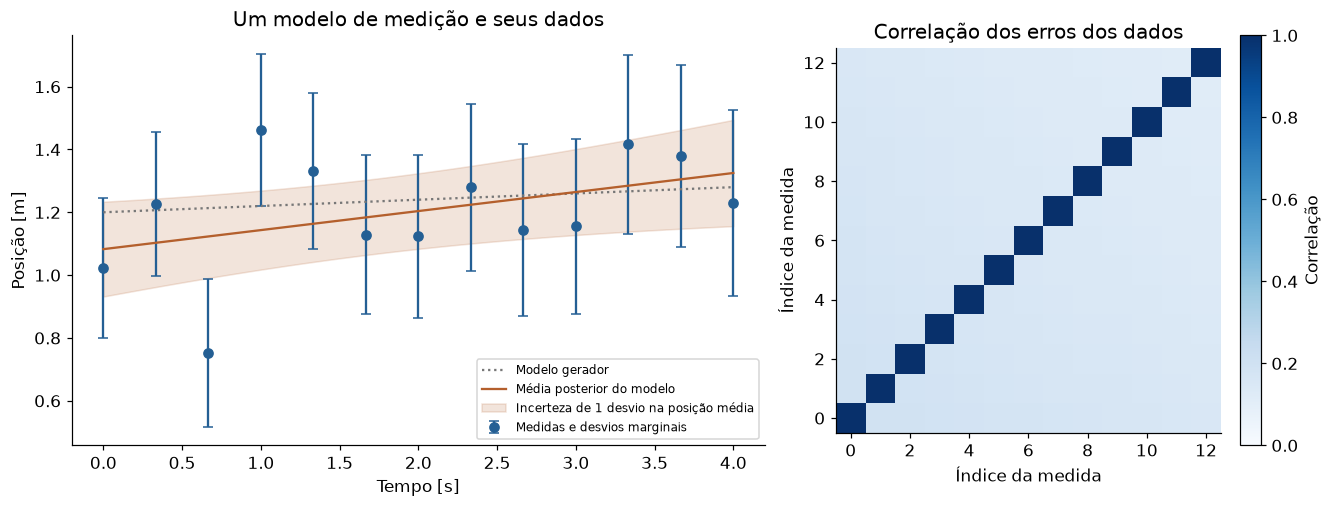

In [5]:
# Cria mais instantes somente para desenhar uma curva contínua.
t_plot = np.linspace(t.min(), t.max(), 250)
# Escreve o mesmo modelo nos instantes usados no desenho.
X_plot = np.column_stack((np.ones(t_plot.size), t_plot))
# Calcula a posição média prevista com a média posterior dos parâmetros.
mu_plot = X_plot @ m
# Propaga a covariância dos parâmetros para a incerteza da posição média.
sigma_modelo = np.sqrt(np.einsum("ni,ij,nj->n", X_plot, Sigma, X_plot))
# Divide cada covariância pelos desvios para obter correlações adimensionais.
corr_dados = C_dados / np.sqrt(np.outer(np.diag(C_dados), np.diag(C_dados)))

# Cria os painéis da figura; as linhas seguintes desenham as comparações.
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.8, 1]},
                        layout="constrained")
axs[0].errorbar(t, dados, yerr=np.sqrt(np.diag(C_dados)), fmt="o", color=AZUL,
                capsize=3, label="Medidas e desvios marginais")
axs[0].plot(t_plot, X_plot @ theta_gerador, color=CINZA, ls=":", label="Modelo gerador")
axs[0].plot(t_plot, mu_plot, color=LARANJA, label="Média posterior do modelo")
axs[0].fill_between(t_plot, mu_plot-sigma_modelo, mu_plot+sigma_modelo,
                     color=LARANJA, alpha=.17, label="Incerteza de 1 desvio na posição média")
axs[0].set(xlabel="Tempo [s]", ylabel="Posição [m]", title="Um modelo de medição e seus dados")
axs[0].legend(fontsize=8)
# Desenha o mapa de correlação dos erros das medidas.
im = axs[1].imshow(corr_dados, vmin=0, vmax=1, cmap="Blues", origin="lower")
axs[1].set(xlabel="Índice da medida", ylabel="Índice da medida", title="Correlação dos erros dos dados")
fig.colorbar(im, ax=axs[1], label="Correlação")
# Exibe a figura e salva as versões PNG e SVG.
mostrar_figura("01_dados_e_covariancia", fig)


As barras mostram os desvios marginais $\sqrt{C_{ii}}$. Elas não mostram, sozinhas, como os erros se relacionam. No painel da direita, os elementos fora da diagonal revelam a correlação gerada pela calibração compartilhada. É essa matriz completa que entrou na likelihood e no ajuste.

A faixa da curva representa a incerteza sobre a **posição média prevista**, $\operatorname{Var}[\mu(t)\mid d]=X(t)\Sigma X(t)^T$. Uma faixa preditiva para novas medidas também precisaria incluir seu ruído e sua relação com a calibração.

O parâmetro gerador aparece porque os dados são simulados; em um experimento real, ele não estaria disponível para julgar o ajuste. Até aqui, o erro compartilhado apareceu em $C$; na seção 1.8 verificaremos o efeito previsto sobre $a$ e $v$.


## 1.5. Relação entre matriz de Fisher e informação

A definição de informação esperada utiliza a distribuição dos dados sob parâmetros fixos. Definindo o *score* $s_a=\partial_a\log\mathcal L$, com $a$ sendo a derivada em relação aos PARÂMETROS. 

$$
F^{\rm exp}_{ab}=\mathbb E_{d\mid\theta}[s_as_b]
=-\mathbb E_{d\mid\theta}[\partial_a\partial_b\log\mathcal L],
$$

sob as condições de regularidade que permitem diferenciar sob a integral.

Para um modelo gaussiano cuja covariância não dependa dos dados, escrevendo $\mu_{,a}=\partial_a\mu$,

$$
s_a=\mu_{,a}^TC^{-1}r.
$$

Como $\mathbb E[r]=0$ e $\mathbb E[rr^T]=C$ sob o modelo verdadeiro,

$$
\boxed{F^{\rm exp}_{ab}=\mu_{,a}^TC^{-1}\mu_{,b}},
\qquad F^{\rm exp}=J^TC^{-1}J,
$$

onde $J_{ia}=\partial_a\mu_i$. No modelo linear, $J=X$ e recuperamos a matriz já obtida pelas equações anterioresç

### Três matrizes parecidas que trazem informações diferentes

A curvatura observada da log-likelihood negativa, ou seja, considerando os dados medidos, é

$$
H^{\rm obs}_{ab}=
\mu_{,a}^TC^{-1}\mu_{,b}
-\mu_{,ab}^TC^{-1}r.
$$

No caso linear as derivadas segundas em relação ao parâmetros são todas 0, $\mu_{,ab}=0$, portanto $H^{\rm obs}=F^{\rm exp}=F$ para qualquer conjunto de dados. Num modelo não linear, o termo com o resíduo pode permanecer mesmo num máximo da likelihood, isso é importante para interpretarmos melhor o DALI, que se expande para modelos não lineares.

| Matriz | O que descreve? | Nesta aplicação linear |
|---|---|---|
| $F^{\rm exp}$ | Informação média em dados que poderiam ser observados. | $X^TC^{-1}X$. |
| $H^{\rm obs}$ | Curvatura da log-likelihood negativa nos dados observados. | Igual a $F^{\rm exp}$. |
| $H^{\rm post}$ | Curvatura de $-\log p(\theta\mid d)$ no ponto considerado. | $F+S_0^{-1}=Q$. |

Para uma posterior geral com máximo interior $\widehat\theta$,

$$
-\log p(\widehat\theta+\Delta\mid d)
\simeq -\log p(\widehat\theta\mid d)
+\frac12\Delta^TH^{\rm post}\Delta.
$$

A inversa de $H^{\rm post}$ descreve a covariância da gaussiana **local**.

In [6]:
# As segundas derivadas de um modelo linear nos parâmetros são zero.
segundas_lineares = np.zeros((N, 2, 2))
# Calcula a curvatura observada e mantém explícito o termo com o resíduo.
H_obs_linear = dali.observed_gaussian_hessian(
    dados-X @ ajuste.mle, X, segundas_lineares, C_dados
)
# Confere a igualdade entre Fisher e a curvatura observada no modelo linear.
assert np.allclose(F, H_obs_linear)
# Confere a soma das precisões da likelihood e da prior.
assert np.allclose(Q, F + np.linalg.solve(S0, np.eye(2)))
# Confere que a precisão e a covariância posterior são inversas.
assert np.allclose(Q @ Sigma, np.eye(2))
print("Modelo linear: informação esperada = curvatura observada.")
print("A covariância posterior é a inversa de Q = F + precisão da prior.")


Modelo linear: informação esperada = curvatura observada.
A covariância posterior é a inversa de Q = F + precisão da prior.


## 1.6. Convariância e Geometria

No nosso caso, a posterior normalizada é

$$
p(\theta\mid d)=\frac{|Q|^{1/2}}{(2\pi)^{p/2}}
\exp\!\left[-\frac12(\theta-m)^TQ(\theta-m)\right].
$$

Na transformação $z=Q^{1/2}(\theta-m)$, a distribuição se torna uma normal padrão. Assim, $\mathbb E[zz^T]=I$ e

$$
\boxed{\operatorname{Cov}(\theta\mid d)=Q^{-1}=\Sigma}.
$$

As entradas diagonais de $\Sigma$ são as variâncias marginais; $\Sigma_{av}$ mede como as flutuações de $a$ e $v$ se relacionam. As unidades são $\Sigma_{aa}$ em $\mathrm m^2$, $\Sigma_{av}$ em $\mathrm{m^2\,s^{-1}}$ e $\Sigma_{vv}$ em $\mathrm{m^2\,s^{-2}}$. A correlação

$$
\rho_{av}=\frac{\Sigma_{av}}{\sqrt{\Sigma_{aa}\Sigma_{vv}}}
$$

é adimensional. Como medimos em $t\ge0$, uma posição inicial maior pode ser compensada por uma velocidade menor, produzindo anticorrelação.

Para uma pequena mudança nos parâmetros, $\delta\mu\simeq J\delta\theta$. A distância entre as previsões, ponderada pelo ruído, é

$$
\|\delta\mu\|_{C^{-1}}^2= \delta\mu^{T} C^{-1} \delta \mu = \delta\theta ^{T} J^{T} C^{-1} J \delta \theta = \delta\theta^TF^{\rm exp}\delta\theta.
$$

Uma direção de grande informação (muitos dados) altera bastante as previsões em relação ao ruído; sua incerteza tende a ser menor. Uma direção pouco restringida (poucos dados) produz alterações difíceis de distinguir nos dados, incertezas maiores.

### Mudando a escala dos vetores para desenhar as direções

$a$ está em metros e $v$ em metros por segundo. Uma inclinação visual em um gráfico desses números depende das unidades: trocar metros por centímetros já mudaria o desenho. Vamos declarar as escalas do gráfico antes de interpretar seus autovetores:

$$
u_a=\frac{a-m_a}{0.20\,\mathrm m},\qquad
u_v=\frac{v-m_v}{0.05\,\mathrm{m/s}},\qquad
u=S^{-1}(\theta-m).
$$

Aqui $S=\operatorname{diag}(0.20\,\mathrm m,0.05\,\mathrm{m/s})$. As escalas são escolhas de visualização e podem ser alteradas. Não acrescentam dados ou prior. Substituindo $\theta-m=Su$ na mesma forma quadrática,

$$
(\theta-m)^TQ(\theta-m)=u^T\underbrace{(S^TQS)}_{Q_u}u.
$$

Assim, **$Q_u$ é a mesma precisão escrita nas coordenadas do gráfico**. Seus autovetores dão as direções principais e seus autovalores $\lambda_i$ dão semieixos $\sqrt{q/\lambda_i}$ para a elipse $u^TQ_uu=q$. Reescalar não elimina a correlação nem garante variâncias unitárias. Continuaremos calculando e apresentando as incertezas físicas com $\Sigma$; não precisamos de outra matriz de covariância para este gráfico.

Em dois parâmetros gaussianos, $q$ segue $\chi^2$ com dois graus de liberdade. As regiões conjuntas de 68,3% e 95,4% usam $q\simeq2.30$ e $6.17$. $q=1$ contém apenas 39,3% da massa conjunta; já o intervalo marginal de um desvio contém cerca de 68,3% em uma dimensão. As elipses e as marginais serão comparadas com a integração na seção seguinte.


In [7]:
# Escolhe as unidades do gráfico adimensional; altere sem mudar o ajuste físico.
escala = np.diag([0.20, 0.05])
# Calcula a transformação que divide os deslocamentos por essas escalas.
escala_inv = np.linalg.solve(escala, np.eye(2))
# Reescreve a mesma forma quadrática nas coordenadas adimensionais.
Q_u = escala.T @ Q @ escala
# Encontra as larguras e direções principais nessa escala declarada.
autovalores, autovetores = np.linalg.eigh(Q_u)
# Calcula a correlação entre os parâmetros a e v.
rho = Sigma[0, 1] / np.sqrt(Sigma[0, 0]*Sigma[1, 1])

# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("03_geometria", pd.DataFrame({
    "Direção adimensional": [1, 2],
    "Autovalor de Q_u": autovalores,
    "Desvio na direção": 1/np.sqrt(autovalores),
    "Semieixo da região de 68,3%": np.sqrt(chi2.ppf(.683, 2)/autovalores),
}))
# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("03_probabilidade_conjunta", pd.DataFrame({
    "Massa conjunta": [.683, .954],
    "q em duas dimensões": chi2.ppf([.683, .954], df=2),
}))
print(f"Correlação entre a e v: {rho:.6f}")
print(f"Massa conjunta com q <= 1: {chi2.cdf(1, 2):.6f}")


,Direção adimensional,Autovalor de Q_u,Desvio na direção,"Semieixo da região de 68,3%"
0,1,0.711048,1.185907,1.797620
1,2,3.509378,0.533808,0.809156


,Massa conjunta,q em duas dimensões
0,0.683,2.297707
1,0.954,6.158228


Correlação entre a e v: -0.610382
Massa conjunta com q <= 1: 0.393469


## 1.7. A integração numérica recupera a solução analítica?

Vamos avaliar diretamente o produto $\mathcal L(\theta)\pi(\theta)$ numa malha. A integração será feita por Simpson nos dois eixos. Isso verifica simultaneamente a normalização, as médias, a covariância e as marginais.

Usaremos $a$ no eixo horizontal e $v$ no vertical: uma matriz tabulada terá a forma `densidade[índice_v, índice_a]`. As integrais serão calculadas com as coordenadas dos eixos; somar densidades sem as larguras das células não representa uma probabilidade.

O domínio se estenderá por oito desvios marginais em cada direção em torno da média analítica. Esse recorte é uma **escolha de integração**, não uma nova fronteira da prior. Vamos refinar a malha e verificar que ampliar o domínio não altera os resultados.

Para evitar subfluxo numérico, a normalização usará uma constante de deslocamento no logaritmo:

$$
Z=e^s\int \exp[\log\mathcal L+\log\pi-s]\,d\theta.
$$

Como a prior é gaussiana e o modelo é linear, há ainda uma verificação independente da normalização. A distribuição preditiva anterior dos dados é

$$
d\sim\mathcal N(Xm_0,\ C+XS_0X^T),
$$

portanto a densidade dessa normal nos dados observados fornece $Z$ analiticamente. Não usaremos seu valor como teste de qualidade do ajuste nem faremos comparação de modelos neste bloco.

Nos gráficos, também construiremos regiões de **maior densidade posterior**, ou HPD. Escolhemos um limiar $c$ tal que a região $p(\theta\mid d)\ge c$ contenha a probabilidade desejada. Na malha, ordenamos os nós por densidade e acumulamos suas massas com os pesos da quadratura. Essa escolha permite comparar regiões com o mesmo conteúdo de probabilidade, inclusive quando seus contornos deixam de ser elipses. A localização do contorno ainda tem erro de discretização.


In [8]:
def malha_gaussiana(media, covariancia, n=201, largura=8.0):
    """Eixos de integração e pontos em forma (n_y, n_x, 2)."""
    # Extrai os desvios marginais para definir o alcance da malha.
    desvios = np.sqrt(np.diag(covariancia))
    # Escolhe os pontos do eixo a para a integração.
    eixo_a = np.linspace(media[0]-largura*desvios[0], media[0]+largura*desvios[0], n)
    # Escolhe os pontos do eixo v para a integração.
    eixo_v = np.linspace(media[1]-largura*desvios[1], media[1]+largura*desvios[1], n)
    # Combina os eixos para avaliar todos os pares de parâmetros.
    aa, vv = np.meshgrid(eixo_a, eixo_v)
    return eixo_a, eixo_v, np.stack((aa, vv), axis=-1)

def log_likelihood_linear(pontos):
    # Subtrai de cada dado a previsão para cada ponto de parâmetros.
    residuos = dados - np.asarray(pontos) @ X.T
    return dali.gaussian_logpdf(residuos, np.zeros(N), C_dados)

# Escolhe os pontos do eixo a para a integração.
eixo_a, eixo_v, pontos = malha_gaussiana(m, Sigma)
# Soma log-likelihood e log-prior, mantendo suas normalizações.
log_produto = log_likelihood_linear(pontos) + dali.gaussian_logpdf(pontos, m0, S0)
# Normaliza a posterior na malha e obtém o log da integral L vezes prior.
pdf_grid, log_Z_grid = dali.normalize_log_grid(log_produto, eixo_a, eixo_v)
# Integra a média e a covariância na malha.
media_grid, cov_grid = dali.grid_moments_2d(pdf_grid, eixo_a, eixo_v)
# Avalia a densidade gaussiana exata nos mesmos pontos.
pdf_analitica = np.exp(dali.gaussian_logpdf(pontos, m, Sigma))
# Calcula a evidência pela distribuição preditiva anterior dos dados.
log_Z_analitico = float(multivariate_normal.logpdf(dados, mean=X @ m0,
                                                cov=C_dados + X @ S0 @ X.T))
# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("04_analitico_vs_malha", pd.DataFrame({
    "Quantidade": ["média de a [m]", "média de v [m/s]", "Var(a) [m²]",
                   "Cov(a,v) [m²/s]", "Var(v) [m²/s²]", "log Z"],
    "Analítica": [m[0], m[1], Sigma[0,0], Sigma[0,1], Sigma[1,1], log_Z_analitico],
    "Malha": [media_grid[0], media_grid[1], cov_grid[0,0], cov_grid[0,1],
              cov_grid[1,1], log_Z_grid],
}).assign(**{"Erro absoluto": lambda df: np.abs(df["Malha"]-df["Analítica"])}))
# Confere a média ou sua estabilidade dentro da tolerância declarada.
assert np.allclose(media_grid, m, atol=1e-9)
# Confere a covariância ou sua estabilidade dentro da tolerância declarada.
assert np.allclose(cov_grid, Sigma, atol=1e-9)
# Confere a normalização numérica usando a evidência analítica.
assert abs(log_Z_grid-log_Z_analitico) < 1e-8


,Quantidade,Analítica,Malha,Erro absoluto
0,média de a [m],1.082649,1.082649,0.000000e+00
1,média de v [m/s],0.060608,0.060608,2.081668e-17
2,Var(a) [m²],0.022768,0.022768,2.518818e-15
3,"Cov(a,v) [m²/s]",-0.004878,-0.004878,7.884318e-16
4,Var(v) [m²/s²],0.002805,0.002805,3.113829e-16
5,log Z,-5.936931,-5.936931,3.828937e-12


In [9]:
# Prepara a lista que reunirá os erros de cada malha.
linhas = []
# Varia resolução ou domínio para verificar a integração.
for n, largura in [(51, 8.0), (101, 8.0), (201, 8.0), (201, 10.0)]:
    # Constrói uma malha para a resolução ou o domínio em teste.
    a_n, v_n, pts_n = malha_gaussiana(m, Sigma, n=n, largura=largura)
    # Reavalia o mesmo produto likelihood vezes prior nessa malha.
    log_n = log_likelihood_linear(pts_n) + dali.gaussian_logpdf(pts_n, m0, S0)
    # Normaliza a densidade na malha em teste.
    p_n, lz_n = dali.normalize_log_grid(log_n, a_n, v_n)
    # Recalcula os momentos para comparar com a resposta analítica.
    m_n, S_n = dali.grid_moments_2d(p_n, a_n, v_n)
    linhas.append({"Nós por eixo": n, "Largura em desvios": largura,
                   "Erro máximo na média": np.max(np.abs(m_n-m)),
                   "Erro máximo na covariância": np.max(np.abs(S_n-Sigma)),
                   "Erro em log Z": abs(lz_n-log_Z_analitico)})
# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("05_refinamento_gaussiano", pd.DataFrame(linhas))


,Nós por eixo,Largura em desvios,Erro máximo na média,Erro máximo na covariância,Erro em log Z
0,51,8.0,2.220446e-16,2.827599e-15,3.828049e-12
1,101,8.0,2.220446e-16,2.550044e-15,3.828937e-12
2,201,8.0,2.081668e-17,2.518818e-15,3.828937e-12
3,201,10.0,2.220446e-16,8.673617e-19,3.831602e-12


### Marginalização com a matriz de Fisher

Na gaussiana, as marginais têm variâncias $\Sigma_{aa}$ e $\Sigma_{vv}$. Se fixarmos o outro parâmetro em sua média, as variâncias condicionais são $1/Q_{aa}$ e $1/Q_{vv}$, respectivamente. Com correlação não nula, elas são menores que as variâncias marginais.

Em dois parâmetros,

$$
\sigma^2_{a\mid v=m_v}=\Sigma_{aa}-\frac{\Sigma_{av}^2}{\Sigma_{vv}},
\qquad
\sigma^2_{v\mid a=m_a}=\Sigma_{vv}-\frac{\Sigma_{av}^2}{\Sigma_{aa}}.
$$

Integrar considera a incerteza sobre o parâmetro que não nos interessa. Fixá-lo introduz informação adicional: seu valor foi tomado como conhecido. Isso explica por que um corte normalizado tende a ser mais estreito que a marginal.


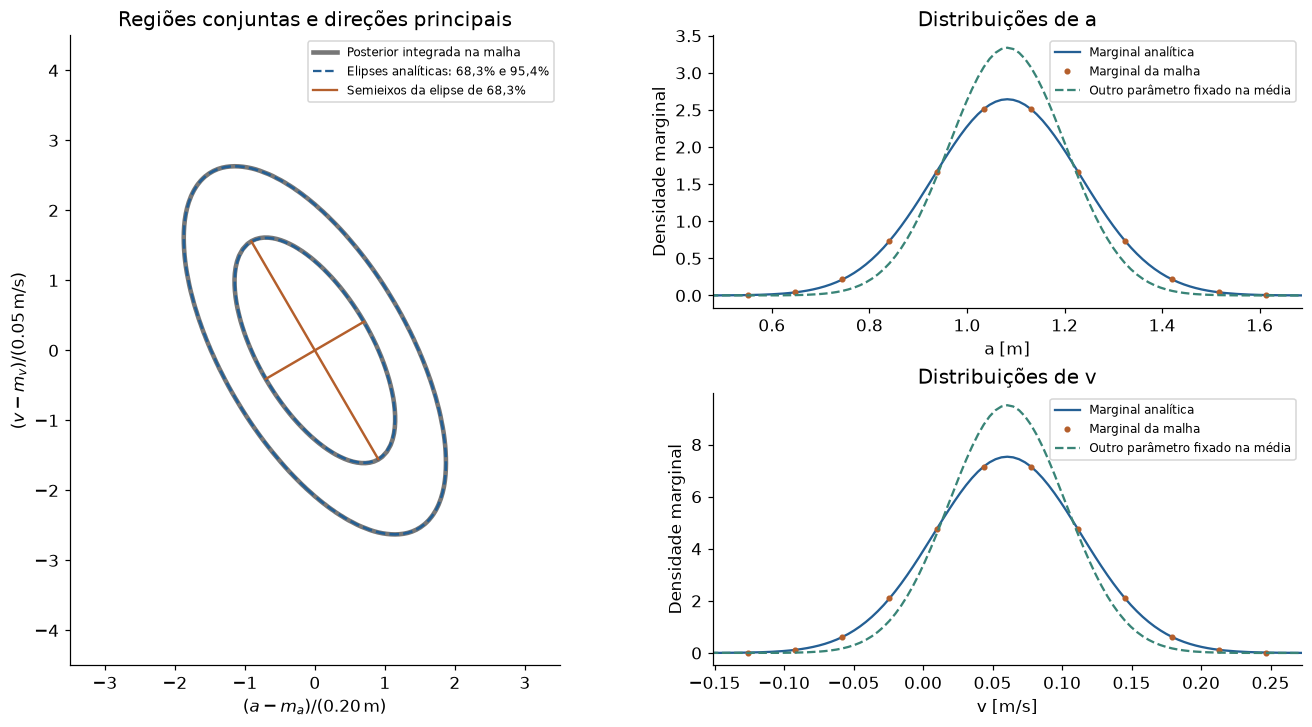

In [10]:
# Integra sobre v para obter a marginal de a.
pa_grid = simpson(pdf_grid, x=eixo_v, axis=0)
# Integra sobre a para obter a marginal de v.
pv_grid = simpson(pdf_grid, x=eixo_a, axis=1)
# Reescreve o eixo a na escala adimensional do gráfico conjunto.
u0 = (pontos[...,0]-m[0])/escala[0,0]
# Reescreve o eixo v na escala adimensional do gráfico conjunto.
u1 = (pontos[...,1]-m[1])/escala[1,1]
# Encontra os níveis de densidade das regiões HPD de 68,3% e 95,4%.
limiares = np.sort(dali.hpd_thresholds_2d(pdf_grid, eixo_a, eixo_v))

# Cria os painéis da figura; as linhas seguintes desenham as comparações.
fig = plt.figure(figsize=(12, 6.5), layout="constrained")
# Divide a figura entre o painel conjunto e os dois painéis marginais.
gs = fig.add_gridspec(2, 2, width_ratios=[1.1, 1])
# Associa nomes aos três painéis para desenhar em cada um.
axj, axa, axv = fig.add_subplot(gs[:,0]), fig.add_subplot(gs[0,1]), fig.add_subplot(gs[1,1])
axj.contour(u0, u1, pdf_grid, levels=limiares, colors=CINZA, linewidths=3)
# Percorre as duas probabilidades conjuntas que serão desenhadas.
for prob in (.683, .954):
    # Calcula a elipse analítica com a probabilidade conjunta escolhida.
    elipse = dali.gaussian_ellipse(m, Sigma, prob)
    # Aplica à elipse a mesma mudança de escala usada na malha.
    elipse_u = (elipse-m) @ escala_inv.T
    axj.plot(elipse_u[:,0], elipse_u[:,1], color=AZUL, ls="--", lw=1.7)
# Percorre as duas direções principais da precisão.
for k in range(2):
    # Calcula o semieixo da elipse de 68,3% nessa direção principal.
    vetor = np.sqrt(chi2.ppf(.683, 2)/autovalores[k]) * autovetores[:,k]
    axj.plot([-vetor[0], vetor[0]], [-vetor[1], vetor[1]], color=LARANJA, lw=1.6)
axj.set(xlabel=r"$(a-m_a)/(0.20\,\mathrm{m})$",
        ylabel=r"$(v-m_v)/(0.05\,\mathrm{m/s})$", title="Regiões conjuntas e direções principais")
axj.set_xlim(-3.5, 3.5); axj.set_ylim(-4.5, 4.5)
axj.set_aspect("equal", adjustable="box")
axj.plot([], [], color=CINZA, lw=3, label="Posterior integrada na malha")
axj.plot([], [], color=AZUL, ls="--", label="Elipses analíticas: 68,3% e 95,4%")
axj.plot([], [], color=LARANJA, label="Semieixos da elipse de 68,3%")
axj.legend(fontsize=8)
# Repete a comparação entre marginal e corte para cada parâmetro.
for ax, eixo, marginal, i, nome, unidade in [
    (axa, eixo_a, pa_grid, 0, "a", "m"), (axv, eixo_v, pv_grid, 1, "v", "m/s")]:
    ax.plot(eixo, norm.pdf(eixo, m[i], np.sqrt(Sigma[i,i])), color=AZUL,
            label="Marginal analítica")
    ax.plot(eixo[::8], marginal[::8], ".", color=LARANJA, label="Marginal da malha")
    ax.plot(eixo, norm.pdf(eixo, m[i], np.sqrt(1/Q[i,i])), ls="--", color=VERDE,
            label="Outro parâmetro fixado na média")
    ax.set(xlabel=f"{nome} [{unidade}]", ylabel="Densidade marginal", title=f"Distribuições de {nome}")
    ax.set_xlim(m[i]-4*np.sqrt(Sigma[i,i]), m[i]+4*np.sqrt(Sigma[i,i]))
    ax.legend(fontsize=8)
# Exibe a figura e salva as versões PNG e SVG.
mostrar_figura("02_geometria_e_marginais", fig)


## 1.8. Covariância dos dados, dos parâmetros e de estimadores

É útil separar três perguntas:

1. **Como os erros das posições flutuariam se repetíssemos o experimento?** A resposta está em $C$, uma matriz $N\times N$.
2. **Quanto os parâmetros ainda podem variar depois destes dados e desta prior?** A resposta está na covariância posterior $\Sigma$, uma matriz $p\times p$.
3. **Como a estimativa de máxima likelihood variaria entre repetições do experimento?** Essa é a covariância amostral de um estimador.

No caso linear, $\widehat\theta_{\rm ML}=\theta_{\rm verdadeiro}+F^{-1}X^TC^{-1}\varepsilon$. Portanto,

$$
\operatorname{Cov}_{d\mid\theta}(\widehat\theta_{\rm ML})
=F^{-1}X^TC^{-1}CC^{-1}XF^{-1}=F^{-1}.
$$

A igualdade numérica com a covariância posterior no limite de prior ampla é uma propriedade deste modelo. Com a prior gaussiana, a covariância posterior é $(F+S_0^{-1})^{-1}$.

### O que o erro compartilhado faz fisicamente?

Um deslocamento de calibração é indistinguível de uma alteração em $a$, mas não altera as diferenças de posição que informam $v$. Neste modelo específico, a covariância da likelihood com calibração é

$$
F_C^{-1}=F_{\rm ind}^{-1}+
\begin{pmatrix}\tau_{\rm cal}^2&0\\0&0\end{pmatrix}.
$$

Assim, a incerteza compartilhada cria um piso adicional para a posição inicial.


In [11]:
# Repete o ajuste com somente os erros independentes.
ajuste_ind = dali.linear_gaussian_posterior(X, dados, C_ind)
# Repete o ajuste com o erro comum, mantendo os mesmos dados.
ajuste_cor = dali.linear_gaussian_posterior(X, dados, C_dados)
# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("06_efeito_calibracao", pd.DataFrame({
    "Caso": ["Erros independentes", "Com calibração compartilhada"],
    "sigma de a na likelihood [m]": [np.sqrt(ajuste_ind.covariance[0,0]),
                                     np.sqrt(ajuste_cor.covariance[0,0])],
    "sigma de v na likelihood [m/s]": [np.sqrt(ajuste_ind.covariance[1,1]),
                                       np.sqrt(ajuste_cor.covariance[1,1])],
}))
# Confere que só Var(a) recebe o acréscimo tau_cal² previsto.
assert np.allclose(ajuste_cor.covariance-ajuste_ind.covariance,
                  [[tau_cal**2, 0], [0, 0]], atol=1e-12)


,Caso,sigma de a na likelihood [m],sigma de v na likelihood [m/s]
0,Erros independentes,0.113029,0.052976
1,Com calibração compartilhada,0.150915,0.052976


## 1.9. Uma prior informativa muda o problema de inferência

Até aqui usamos uma prior ampla: desvios de $10\,\mathrm m$ em $a$ e $3\,\mathrm{m/s}$ em $v$, centrada em zero. Ela muda muito pouco na região favorecida pela likelihood. Agora queremos responder a uma pergunta diferente: **o que muda se tivermos uma medida anterior e independente da velocidade?**

Manteremos os dados, o modelo e $C$. A única troca será a prior de $v$:

$$
\pi_{\rm ampla}(v)=\mathcal N(0,3^2)
\quad\longrightarrow\quad
\pi_{\rm info}(v)=\mathcal N(0.03,0.04^2),
$$

com velocidades em $\mathrm{m/s}$. A prior de $a$ permanece igual. A nova informação é ilustrativa e não foi estimada dos dados que já usamos.

O fator da likelihood permanece o mesmo. Ao multiplicá-lo pela nova prior, seus expoentes somam-se:

$$
Q_{\rm info}=F+S_{0,\rm info}^{-1},\qquad
Q_{\rm info}m_{\rm info}=F\widehat\theta_{\rm ML}
+S_{0,\rm info}^{-1}m_{0,\rm info}.
$$

A primeira equação mostra por que somamos **precisões**. A segunda mostra como os centros da likelihood e da prior participam da média final. Como $a$ e $v$ são anticorrelacionados, favorecer velocidades menores também pode favorecer posições iniciais maiores.

Antes de olhar o gráfico, esperamos uma marginal de $v$ mais estreita e um centro que se desloque em direção à informação anterior. No painel da direita, a curva verde é a prior usada sozinha; as outras duas são posteriors. No painel conjunto, linhas contínuas delimitam 68,3% e tracejadas delimitam 95,4%. A tabela permite verificar como a mudança se transmite a $a$.

Essa posterior ainda é exatamente gaussiana. Portanto, esta comparação mostra o papel da prior; a fronteira da seção 1.10 será o passo que altera o suporte e quebra essa forma gaussiana.


,Caso,Média de a [m],Média de v [m/s],sigma de a [m],sigma de v [m/s]
0,Prior ampla,1.082649,0.060608,0.150889,0.052965
1,Prior informativa em v,1.116534,0.041121,0.131781,0.031922


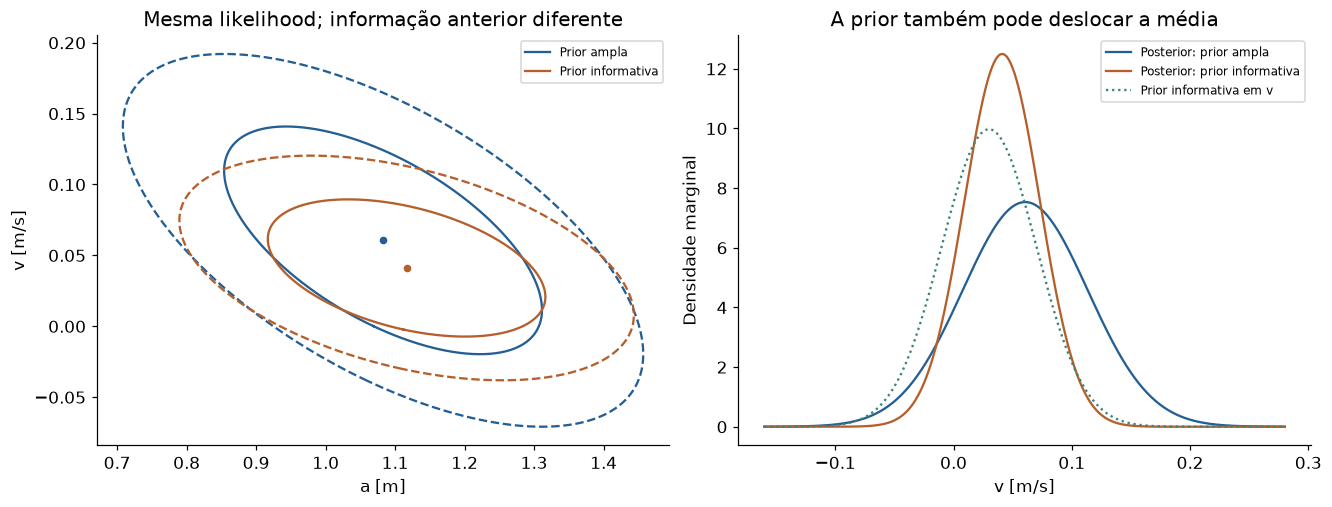

In [12]:
# Escolhe a média da informação anterior sobre v; altere para testar outro centro.
m0_info = np.array([0.0, 0.030])
# Mantém a prior de a e escolhe desvio 0.040 m/s em v; altere para outra força da prior.
S0_info = np.diag([10.0**2, 0.040**2])
# Refaz a posterior com a nova prior e com a mesma likelihood.
ajuste_info = dali.linear_gaussian_posterior(X, dados, C_dados, m0_info, S0_info)

# Cria uma malha que cobre a nova posterior.
a_info, v_info, pts_info = malha_gaussiana(ajuste_info.mean, ajuste_info.covariance)
# Normaliza a posterior formada pela likelihood original e pela nova prior.
p_info, _ = dali.normalize_log_grid(
    log_likelihood_linear(pts_info)+dali.gaussian_logpdf(pts_info, m0_info, S0_info), a_info, v_info
)
# Confere a nova média e covariância por integração.
m_info_grid, S_info_grid = dali.grid_moments_2d(p_info, a_info, v_info)
# Confere a média ou sua estabilidade dentro da tolerância declarada.
assert np.allclose(m_info_grid, ajuste_info.mean, atol=1e-9)
# Confere a covariância ou sua estabilidade dentro da tolerância declarada.
assert np.allclose(S_info_grid, ajuste_info.covariance, atol=1e-9)

# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("07_prior_gaussiana", pd.DataFrame({
    "Caso": ["Prior ampla", "Prior informativa em v"],
    "Média de a [m]": [m[0], ajuste_info.mean[0]],
    "Média de v [m/s]": [m[1], ajuste_info.mean[1]],
    "sigma de a [m]": [np.sqrt(Sigma[0,0]), np.sqrt(ajuste_info.covariance[0,0])],
    "sigma de v [m/s]": [np.sqrt(Sigma[1,1]), np.sqrt(ajuste_info.covariance[1,1])],
}))

# Cria os painéis da figura; as linhas seguintes desenham as comparações.
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
# Compara as duas escolhas de prior com a mesma convenção de cores.
for resultado, cor, nome in [(ajuste, AZUL, "Prior ampla"), (ajuste_info, LARANJA, "Prior informativa")]:
    # Percorre as duas probabilidades conjuntas que serão desenhadas.
    for prob, estilo in [(.683, "-"), (.954, "--")]:
        # Calcula uma elipse analítica para o caso e a probabilidade desta iteração.
        curva = dali.gaussian_ellipse(resultado.mean, resultado.covariance, prob)
        axs[0].plot(curva[:,0], curva[:,1], color=cor, ls=estilo,
                    label=nome if prob==.683 else None)
    axs[0].plot(*resultado.mean, "o", color=cor, ms=4)
    # Escolhe o intervalo em que serão desenhadas as densidades de v.
    v_grafico = np.linspace(-.16, .28, 500)
    axs[1].plot(v_grafico, norm.pdf(v_grafico, resultado.mean[1], np.sqrt(resultado.covariance[1,1])),
                color=cor, label=f"Posterior: {nome.lower()}")
axs[1].plot(v_grafico, norm.pdf(v_grafico, m0_info[1], np.sqrt(S0_info[1,1])),
            color=VERDE, ls=":", label="Prior informativa em v")
axs[0].set(xlabel="a [m]", ylabel="v [m/s]", title="Mesma likelihood; informação anterior diferente")
axs[1].set(xlabel="v [m/s]", ylabel="Densidade marginal", title="A prior também pode deslocar a média")
for ax in axs: ax.legend(fontsize=8)
# Exibe a figura e salva as versões PNG e SVG.
mostrar_figura("03_prior_gaussiana", fig)


## 1.10. Uma fronteira física: mesma curvatura, covariância diferente

Suponha agora que uma informação física adicional selecione movimentos no sentido positivo, incluindo repouso: $v\ge0$. Essa é uma restrição do experimento considerado, uma prior mais restritiva.

Voltaremos à prior ampla do caso-base e a condicionaremos a $v\ge0$. Se $p_0$ denota a posterior gaussiana desse caso, a posterior restringida é

$$
p_+(a,v\mid d)=\frac{p_0(a,v\mid d)\,\mathbf 1_{v\ge0}}{Z_+},
\qquad
Z_+=\int_{v\ge0}p_0(a,v\mid d)\,da\,dv.
$$

$Z_+$ é a **massa aceita pela posterior-base**, não a evidência original dos dados. Os fatores de normalização da prior restringida se cancelam ao normalizar a posterior.

Na região interior permitida, a log-posterior difere da anterior apenas por uma constante; sua Hessiana continua $Q$. Mas a distribuição global é cortada, sua marginal em $v$ se torna assimétrica e seus momentos mudam. Logo, a inversa da curvatura interna não é, em geral, a covariância dessa posterior truncada.

### Referência analítica para a truncagem

Definimos $\sigma_v=\sqrt{\Sigma_{vv}}$, $\alpha=-m_v/\sigma_v$, $Z_+=1-\Phi(\alpha)$ e $\lambda=\varphi(\alpha)/Z_+$, onde $\varphi$ e $\Phi$ são a densidade e a acumulada da normal padrão. A integral por partes da cauda gaussiana dá

$$
\mathbb E[v\mid v\ge0,d]=m_v+\sigma_v\lambda,
\quad
\operatorname{Var}(v\mid v\ge0,d)=\sigma_v^2(1+\alpha\lambda-\lambda^2).
$$

Usando a distribuição condicional gaussiana de $a$ dado $v$, obtemos os momentos conjuntos:

$$
m_+=m+\frac{\Sigma_{:,v}}{\sigma_v}\lambda,
\qquad
\Sigma_+=\Sigma-\frac{\Sigma_{:,v}\Sigma_{v,:}}{\sigma_v^2}
\lambda(\lambda-\alpha).
$$

A notação $\Sigma_{:,v}$ representa a coluna associada a $v$. A mudança da média de $a$ resulta da correlação entre os parâmetros.

**Antes de executar:** se retirarmos a cauda de velocidades negativas, em que sentido a média de $v$ deve mudar? E a de $a$, que é anticorrelacionada com $v$?


In [13]:
# Calcula os momentos exatos ao condicionar a gaussiana a v >= 0.
m_mais, Sigma_mais, massa_aceita = dali.lower_truncated_gaussian_moments(m, Sigma, index=1)
# Extrai os desvios do caso-base para definir a malha truncada.
sigma_a, sigma_v = np.sqrt(np.diag(Sigma))
# Mantém um domínio amplo em a; 321 controla a resolução.
a_mais = np.linspace(m[0]-8*sigma_a, m[0]+8*sigma_a, 321)
# Começa a integração em v=0, a fronteira física declarada.
v_mais = np.linspace(0.0, m[1]+8*sigma_v, 321)
# Forma os pares de coordenadas dentro do domínio permitido.
aa_mais, vv_mais = np.meshgrid(a_mais, v_mais)
# Coloca cada par (a,v) na última dimensão do array.
pts_mais = np.stack((aa_mais, vv_mais), axis=-1)

# Integramos apenas o domínio permitido: não inserimos uma descontinuidade
# artificial no meio da malha de quadratura.
p_mais, log_massa_grid = dali.normalize_log_grid(
    dali.gaussian_logpdf(pts_mais, m, Sigma), a_mais, v_mais
)
# Integra os momentos da posterior truncada para confrontar com as fórmulas.
m_mais_grid, S_mais_grid = dali.grid_moments_2d(p_mais, a_mais, v_mais)
# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("08_fronteira_momentos", pd.DataFrame({
    "Quantidade": ["média de a [m]", "média de v [m/s]", "Var(a) [m²]",
                   "Cov(a,v) [m²/s]", "Var(v) [m²/s²]", "Massa aceita Z+"],
    "Gaussiana sem corte": [m[0], m[1], Sigma[0,0], Sigma[0,1], Sigma[1,1], 1.0],
    "Truncagem analítica": [m_mais[0], m_mais[1], Sigma_mais[0,0], Sigma_mais[0,1],
                           Sigma_mais[1,1], massa_aceita],
    "Truncagem em malha": [m_mais_grid[0], m_mais_grid[1], S_mais_grid[0,0], S_mais_grid[0,1],
                          S_mais_grid[1,1], np.exp(log_massa_grid)],
}))
# Confere a média ou sua estabilidade dentro da tolerância declarada.
assert np.allclose(m_mais_grid, m_mais, atol=1e-7)
# Confere a covariância ou sua estabilidade dentro da tolerância declarada.
assert np.allclose(S_mais_grid, Sigma_mais, atol=1e-8)
print(f"Massa que a gaussiana-base atribui a v < 0: {100*(1-massa_aceita):.4f}%")
print(f"Massa em v >= 0: analítica={massa_aceita:.10f}; malha={np.exp(log_massa_grid):.10f}")


,Quantidade,Gaussiana sem corte,Truncagem analítica,Truncagem em malha
0,média de a [m],1.082649,1.060800,1.060800
1,média de v [m/s],0.060608,0.073174,0.073174
2,Var(a) [m²],0.022768,0.019987,0.019987
3,"Cov(a,v) [m²/s]",-0.004878,-0.003279,-0.003279
4,Var(v) [m²/s²],0.002805,0.001886,0.001886
5,Massa aceita Z+,1.000000,0.873750,0.873750


Massa que a gaussiana-base atribui a v < 0: 12.6250%
Massa em v >= 0: analítica=0.8737500201; malha=0.8737500216


In [14]:
# Reúne os erros ao refinar a malha da posterior truncada.
linhas_mais = []
# Varia resolução ou domínio para verificar a integração.
for n in (81, 161, 321):
    # Constrói uma malha para a resolução ou o domínio em teste.
    a_n = np.linspace(m[0]-8*sigma_a, m[0]+8*sigma_a, n)
    # Monta o eixo vertical da malha em teste.
    v_n = np.linspace(0, m[1]+8*sigma_v, n)
    # Combina os eixos da malha em teste.
    aa_n, vv_n = np.meshgrid(a_n, v_n)
    # Normaliza a densidade na malha em teste.
    p_n, lz_n = dali.normalize_log_grid(
        dali.gaussian_logpdf(np.stack((aa_n, vv_n), -1), m, Sigma), a_n, v_n
    )
    # Calcula os momentos na malha em teste.
    mn, Sn = dali.grid_moments_2d(p_n, a_n, v_n)
    linhas_mais.append({"Nós por eixo": n, "Erro em Z+": abs(np.exp(lz_n)-massa_aceita),
                        "Erro máximo na média": np.max(abs(mn-m_mais)),
                        "Erro máximo na covariância": np.max(abs(Sn-Sigma_mais))})
# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("09_refinamento_fronteira", pd.DataFrame(linhas_mais))


,Nós por eixo,Erro em Z+,Erro máximo na média,Erro máximo na covariância
0,81,3.815598e-07,7.531193e-08,3.613250e-09
1,161,2.378808e-08,4.674238e-09,2.272526e-10
2,321,1.485826e-09,2.916338e-10,1.422619e-11


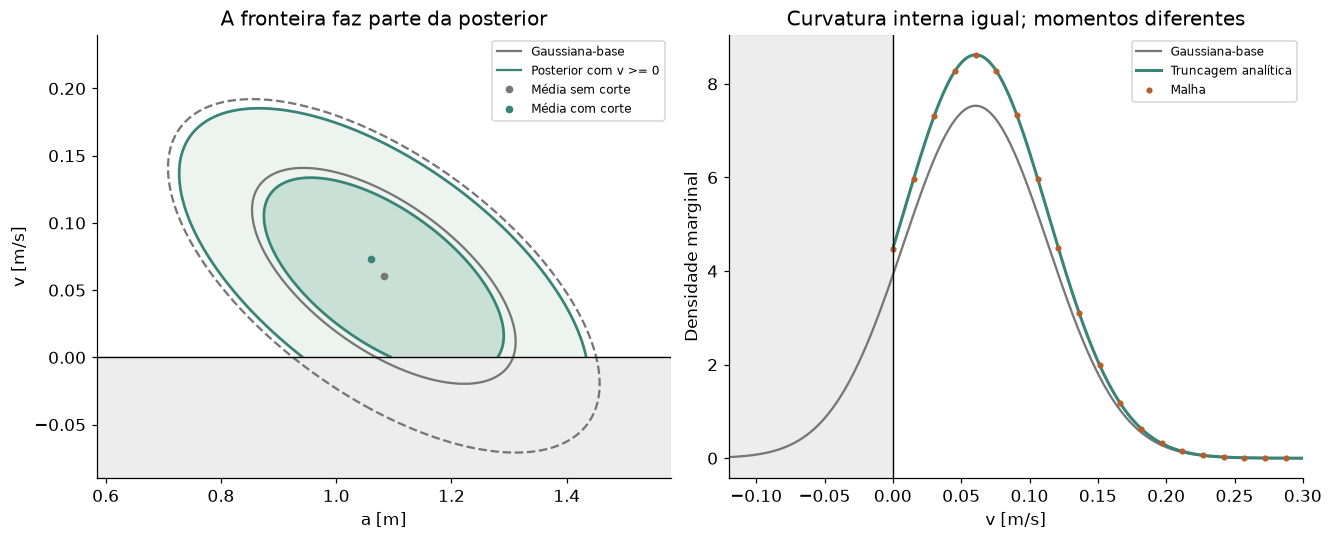

In [15]:
# Integra a para obter a marginal de v depois do corte.
pv_mais = simpson(p_mais, x=a_mais, axis=1)
# Calcula os níveis HPD da posterior que já foi truncada e renormalizada.
lim_mais = np.sort(dali.hpd_thresholds_2d(p_mais, a_mais, v_mais))
# Cria os painéis da figura; as linhas seguintes desenham as comparações.
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
# Percorre as duas probabilidades conjuntas que serão desenhadas.
for prob, estilo in [(.683, "-"), (.954, "--")]:
    # Calcula uma elipse analítica para o caso e a probabilidade desta iteração.
    curva = dali.gaussian_ellipse(m, Sigma, prob)
    axs[0].plot(curva[:,0], curva[:,1], color=CINZA, ls=estilo,
                label="Gaussiana-base" if prob==.683 else None)
axs[0].contourf(aa_mais, vv_mais, p_mais,
                levels=[*lim_mais, p_mais.max()*1.001], colors=["#edf4f0", "#c8e0d6"])
axs[0].contour(aa_mais, vv_mais, p_mais, levels=lim_mais, colors=VERDE, linewidths=1.8)
axs[0].plot([], [], color=VERDE, label="Posterior com v >= 0")
axs[0].axhline(0, color="black", lw=.9)
axs[0].axhspan(-.09, 0, color="#dddddd", alpha=.5)
axs[0].plot(*m, "o", color=CINZA, ms=4, label="Média sem corte")
axs[0].plot(*m_mais, "o", color=VERDE, ms=4, label="Média com corte")
axs[0].set(xlabel="a [m]", ylabel="v [m/s]", title="A fronteira faz parte da posterior",
            xlim=(m[0]-3.3*sigma_a, m[0]+3.3*sigma_a), ylim=(-.09, .24))
# Escolhe um eixo que também mostra a região excluída pela fronteira.
v_des = np.linspace(-.12, .30, 550)
axs[1].plot(v_des, norm.pdf(v_des, m[1], sigma_v), color=CINZA, label="Gaussiana-base")
axs[1].plot(v_mais, norm.pdf(v_mais, m[1], sigma_v)/massa_aceita,
            color=VERDE, lw=2, label="Truncagem analítica")
axs[1].plot(v_mais[::10], pv_mais[::10], ".", color=LARANJA, label="Malha")
axs[1].axvline(0, color="black", lw=.9)
axs[1].axvspan(-.12, 0, color="#dddddd", alpha=.5)
axs[1].set(xlabel="v [m/s]", ylabel="Densidade marginal", title="Curvatura interna igual; momentos diferentes",
            xlim=(-.12, .30))
for ax in axs: ax.legend(fontsize=8)
# Exibe a figura e salva as versões PNG e SVG.
mostrar_figura("04_fronteira_fisica", fig)


As mudanças dos momentos analíticos e numéricos concordam. A condição $v\ge0$ remove massa, exige renormalização e desloca as médias. Dentro do suporte permitido, a curvatura permanece a mesma da gaussiana-base. Neste conjunto de dados, o MAP gaussiano já tem $v>0$ e permanece no mesmo ponto após o corte, embora a média e a covariância mudem.

Se o máximo não restringido estivesse fora do suporte, o MAP restringido poderia estar na fronteira. Nesse caso, a expansão usual em torno de um máximo interior, com gradiente nulo, exigiria ainda mais cuidado.

**Esta não gaussianidade vem da prior e do suporte.** Não precisamos de derivadas superiores da likelihood para representá-la: podemos manter a prior exata. Isso será importante para separar as motivações de DALI no próximo bloco.


## 1.11. Erros gaussianos, priors gaussianas e uma posterior curva

Agora queremos isolar uma origem diferente de não gaussianidade: a **relação não linear entre parâmetros e observáveis**. Usaremos duas medidas adimensionais e parâmetros também adimensionais $q=(q_1,q_2)$:

$$
d=\begin{pmatrix}0\\0\end{pmatrix},\qquad
\mu(q)=\begin{pmatrix}q_1\\q_2-\kappa q_1^2\end{pmatrix},\qquad
C_{\rm nl}=\operatorname{diag}(1,0.4^2),\qquad\kappa=0.65.
$$

O experimento mede uma resposta linear e outra que mistura a segunda coordenada com uma resposta quadrática da primeira. O ruído de ambos os canais é gaussiano. Os dados $(0,0)$ são o valor observado escolhido para este exemplo, e não uma hipótese de ruído com variância nula.

Adotaremos priors gaussianas próprias $q_1\sim\mathcal N(0,3^2)$ e $q_2\sim\mathcal N(0,5^2)$. Assim,

$$
-\log p(q\mid d)=\mathrm{const}
+\frac12q_1^2+\frac{(q_2-\kappa q_1^2)^2}{2(0.4)^2}
+\frac{q_1^2}{2(3)^2}+\frac{q_2^2}{2(5)^2}.
$$

Todos os termos são não negativos e se anulam simultaneamente apenas em $q=(0,0)$, o MAP. O Jacobiano do modelo nesse ponto é a identidade. Como o resíduo é nulo, o Fisher esperado coincide com a curvatura observada ali, e a precisão local da posterior é

$$
Q_{\rm local}=\operatorname{diag}\left(1+\frac19,\;\frac{1}{0.4^2}+\frac1{25}\right).
$$

A curvatura local nem sequer depende de $\kappa$, embora a geometria global da posterior dependa. A likelihood prefere $q_2\approx\kappa q_1^2$: ao nos afastarmos do pico, a região favorecida se curva.

**Antes de executar:** se a elipse local é simétrica em $q_2$ e a região favorecida se curva para $q_2>0$, você espera que a média global de $q_2$ ainda coincida com o MAP?


In [16]:
# Controla a curvatura do modelo; altere para explorar a não linearidade.
kappa = 0.65
# Escolhe as variâncias gaussianas dos dois canais do novo modelo.
C_nl = np.diag([1.0, 0.4**2])
# Escolhe o centro das priors gaussianas do exemplo não linear.
prior_nl_media = np.zeros(2)
# Escolhe as larguras dessas priors; elas são próprias.
prior_nl_cov = np.diag([3.0**2, 5.0**2])
# Usa o Jacobiano no MAP, que é a identidade neste modelo.
F_nl_local = dali.fisher_gaussian(np.eye(2), C_nl)
# Soma a precisão da prior à informação da likelihood no MAP.
Q_nl_local = F_nl_local + np.linalg.solve(prior_nl_cov, np.eye(2))
# Obtém a covariância da gaussiana local.
Sigma_nl_local = np.linalg.solve(Q_nl_local, np.eye(2))

def log_posterior_nl(pontos):
    # Converte os pontos recebidos em um array para avaliar o modelo.
    pontos = np.asarray(pontos)
    # Calcula as duas respostas, incluindo a dependência quadrática.
    modelo = np.stack((pontos[...,0], pontos[...,1]-kappa*pontos[...,0]**2), -1)
    return (dali.gaussian_logpdf(-modelo, [0, 0], C_nl)
            + dali.gaussian_logpdf(pontos, prior_nl_media, prior_nl_cov))

# Escolhe o domínio e a resolução do primeiro parâmetro; refine para testar convergência.
q1 = np.linspace(-5.5, 5.5, 501)
# Escolhe um domínio maior na cauda positiva do segundo parâmetro.
q2 = np.linspace(-3.5, 18.0, 501)
# Combina os eixos para avaliar a posterior completa.
qq1, qq2 = np.meshgrid(q1, q2)
# Agrupa as duas coordenadas de cada ponto da malha.
pts_nl = np.stack((qq1, qq2), -1)
# Normaliza a posterior não linear na malha escolhida.
p_nl, log_Z_nl = dali.normalize_log_grid(log_posterior_nl(pts_nl), q1, q2)
# Calcula a média e a covariância globais, sem a aproximação gaussiana.
m_nl, S_nl = dali.grid_moments_2d(p_nl, q1, q2)
# Integra q1 para obter a marginal do parâmetro q2.
pv_nl = simpson(p_nl, x=q1, axis=1)
# Mede a correlação linear, que não detecta toda dependência não linear.
rho_nl = S_nl[0,1]/np.sqrt(S_nl[0,0]*S_nl[1,1])
# Calcula o terceiro momento central padronizado da marginal de q2.
skew_q2 = simpson((q2-m_nl[1])**3*pv_nl, x=q2)/S_nl[1,1]**1.5

# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("10_posterior_nao_linear", pd.DataFrame({
    "Quantidade": ["média q1", "média q2", "Var(q1)", "Cov(q1,q2)", "Var(q2)"],
    "Gaussiana local": [0.0, 0.0, Sigma_nl_local[0,0], Sigma_nl_local[0,1], Sigma_nl_local[1,1]],
    "Posterior completa em malha": [m_nl[0], m_nl[1], S_nl[0,0], S_nl[0,1], S_nl[1,1]],
}))
print(f"Correlação linear q1-q2 na posterior completa: {rho_nl:.3e}")
print(f"Assimetria da marginal q2 na malha: {skew_q2:.6f}")


,Quantidade,Gaussiana local,Posterior completa em malha
0,média q1,0.000000,3.735882e-18
1,média q2,0.000000,5.417134e-01
2,Var(q1),0.900000,8.387391e-01
3,"Cov(q1,q2)",0.000000,1.278953e-17
4,Var(q2),0.158983,7.109646e-01


Correlação linear q1-q2 na posterior completa: 1.656e-17
Assimetria da marginal q2 na malha: 1.775200


In [17]:
# Guarda os resultados para diferentes resoluções e domínios.
checagens_nl = []
# Varia resolução ou domínio para verificar a integração.
for n, limites in [(251, (-5.5,5.5,-3.5,18)), (501, (-5.5,5.5,-3.5,18)),
                   (601, (-6,6,-4,24))]:
    # Monta o primeiro eixo da malha não linear em teste.
    x_n = np.linspace(limites[0], limites[1], n)
    # Monta o segundo eixo da malha não linear em teste.
    y_n = np.linspace(limites[2], limites[3], n)
    # Forma os pares de coordenadas da malha não linear em teste.
    xx_n, yy_n = np.meshgrid(x_n, y_n)
    # Normaliza a densidade na malha em teste.
    p_n, lz_n = dali.normalize_log_grid(log_posterior_nl(np.stack((xx_n, yy_n), -1)), x_n, y_n)
    # Calcula os momentos na malha em teste.
    mn, Sn = dali.grid_moments_2d(p_n, x_n, y_n)
    checagens_nl.append({"Nós por eixo": n, "Domínio": str(limites),
                         "Média q2": mn[1], "Var(q2)": Sn[1,1], "Var(q1)": Sn[0,0],
                         "Diferença máxima na média vs. principal": np.max(abs(mn-m_nl)),
                         "Diferença máxima na covariância vs. principal": np.max(abs(Sn-S_nl)),
                         "Diferença em log Z vs. principal": abs(lz_n-log_Z_nl)})
# Exibe os resultados desta etapa e salva a mesma tabela em CSV.
mostrar_tabela("11_refinamento_nao_linear", pd.DataFrame(checagens_nl))
# Confere a média ou sua estabilidade dentro da tolerância declarada.
assert np.max(abs(mn-m_nl)) < 1e-7
# Confere a covariância ou sua estabilidade dentro da tolerância declarada.
assert np.max(abs(Sn-S_nl)) < 1e-7


,Nós por eixo,Domínio,Média q2,Var(q2),Var(q1),Diferença máxima na média vs. principal,Diferença máxima na covariância vs. principal,Diferença em log Z vs. principal
0,251,"(-5.5, 5.5, -3.5, 18)",0.541713,0.710965,0.838739,5.551115e-15,9.714451e-14,0.000000e+00
1,501,"(-5.5, 5.5, -3.5, 18)",0.541713,0.710965,0.838739,0.000000e+00,0.000000e+00,0.000000e+00
2,601,"(-6, 6, -4, 24)",0.541713,0.710965,0.838739,4.744829e-10,8.561867e-09,2.626699e-11


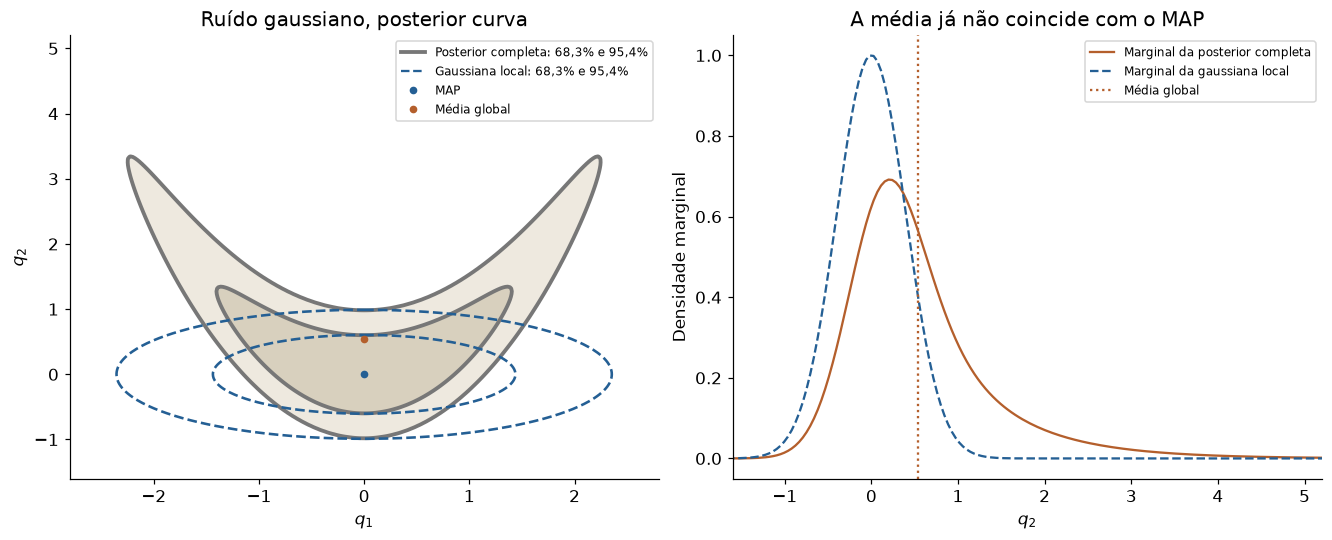

In [18]:
# Calcula os níveis HPD da posterior completa para compará-los com as elipses.
lim_nl = np.sort(dali.hpd_thresholds_2d(p_nl, q1, q2))
# Cria os painéis da figura; as linhas seguintes desenham as comparações.
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
axs[0].contourf(qq1, qq2, p_nl, levels=[*lim_nl, p_nl.max()*1.001],
                colors=["#eee9df", "#d8d0be"])
axs[0].contour(qq1, qq2, p_nl, levels=lim_nl, colors=CINZA, linewidths=2.5)
# Percorre as duas probabilidades conjuntas que serão desenhadas.
for prob in (.683, .954):
    # Calcula uma elipse analítica para o caso e a probabilidade desta iteração.
    curva = dali.gaussian_ellipse([0,0], Sigma_nl_local, prob)
    axs[0].plot(curva[:,0], curva[:,1], color=AZUL, ls="--", lw=1.7)
axs[0].plot([], [], color=CINZA, lw=2.5, label="Posterior completa: 68,3% e 95,4%")
axs[0].plot([], [], color=AZUL, ls="--", label="Gaussiana local: 68,3% e 95,4%")
axs[0].plot(0, 0, "o", color=AZUL, ms=4, label="MAP")
axs[0].plot(*m_nl, "o", color=LARANJA, ms=4, label="Média global")
axs[0].set(xlabel=r"$q_1$", ylabel=r"$q_2$", title="Ruído gaussiano, posterior curva",
            xlim=(-2.8,2.8), ylim=(-1.6,5.2))
axs[1].plot(q2, pv_nl, color=LARANJA, label="Marginal da posterior completa")
axs[1].plot(q2, norm.pdf(q2, 0, np.sqrt(Sigma_nl_local[1,1])), color=AZUL, ls="--",
            label="Marginal da gaussiana local")
axs[1].axvline(m_nl[1], color=LARANJA, ls=":", label="Média global")
axs[1].set(xlabel=r"$q_2$", ylabel="Densidade marginal", title="A média já não coincide com o MAP",
            xlim=(-1.6,5.2))
for ax in axs: ax.legend(fontsize=8)
# Exibe a figura e salva as versões PNG e SVG.
mostrar_figura("05_posterior_curva", fig)


A malha mostra uma média positiva em $q_2$, uma marginal assimétrica e uma largura global que a gaussiana local não recupera. A comparação entre resoluções e domínios permite avaliar se isso poderia ser apenas um erro de integração.

Há um detalhe: a posterior é simétrica em $q_1\to-q_1$. Por isso, sua média em $q_1$ e a covariância linear entre $q_1$ e $q_2$ se anulam. Ainda assim, as coordenadas não são independentes: o valor favorecido de $q_2$ acompanha aproximadamente $\kappa q_1^2$. **Correlação linear nula não implica independência numa distribuição geral.**

Este exemplo não precisou de erros não gaussianos nem de uma fronteira próxima. A forma não gaussiana surge da resposta quadrática do modelo. A aproximação local descreve a região imediatamente próxima ao máximo, mas não toda a massa da posterior.


## 1.12. O que a inversa de Fisher nos diz — e o que ela não diz?

| Situação | Curvatura e covariância | 
|---|---|
| Modelo linear, ruído gaussiano com $C$ fixa, prior aproximadamente constante na região relevante | $F^{-1}$ descreve a covariância no limite de prior ampla. |
| Mesmo modelo e prior gaussiana própria | A posterior é exatamente gaussiana, com covariância $(F+S_0^{-1})^{-1}$. |
| Likelihood quadrática com prior cortada por uma fronteira | A curvatura interna pode permanecer igual, enquanto os momentos globais mudam. |
| Modelo não linear | A curvatura dá uma descrição local; os termos além da forma quadrática podem modificar as regiões e as marginais. |
| Informação esperada singular | Há uma direção que o modelo não identifica na ordem considerada; inverter a matriz não é uma operação válida sem tratar essa situação. |

Para qualquer análise, precisamos declarar o que é a matriz usada, em que ponto foi avaliada, qual prior foi mantida e se a região importante está bem descrita pela expansão local.


## 1.13. E se quisermos ir além da forma gaussiana?

Construímos primeiro um caso em que a forma quadrática é exata e depois encontramos dois mecanismos de não gaussianidade: uma prior com fronteira e uma resposta não linear do modelo.

No primeiro, manter a prior exata já representa o corte. No segundo, mesmo com priors gaussianas suaves e com o máximo bem localizado, a forma quadrática perde a curvatura global da região favorecida. Essa é a motivação para investigar derivadas superiores do modelo.

Podemos então perguntar:

> **E se quisermos caracterizar e recuperar as não gaussianidades? Podemos ir além da expansão até segunda ordem? Por que não simplesmente acrescentar ordens maiores?**

Uma dificuldade já aparece numa dimensão. Se $\psi=-\log p$ e cortarmos sua expansão em

$$
\psi(\Delta)\simeq\psi_0+\frac12h\Delta^2+\frac16t\Delta^3,
$$

com $h>0$ e $t\ne0$, o termo cúbico domina com sinal negativo em uma das caudas. A exponencial $e^{-\psi}$ então cresce sem limite nessa cauda, caso o suporte seja ilimitado. Acrescentar um termo pode destruir a normalização em vez de melhorar a distribuição. Uma prior de suporte finito pode evitar a divergência da integral sem garantir uma boa aproximação.

No próximo bloco, vamos estudar **como DALI reorganiza os termos da expansão**, distinguindo a ordem das derivadas do modelo da potência dos deslocamentos no expoente. A pergunta será como conservar uma construção probabilística bem definida e, ao mesmo tempo, recuperar parte da geometria que Fisher não descreveu.

<a id="bloco-2"></a>

# 2. Hierarquia de DALI

No Bloco 1, a resposta linear dos observáveis produziu uma likelihood exatamente quadrática nos parâmetros. Depois, uma resposta não linear curvou a posterior e mostrou o que a elipse local deixava de representar. Vamos agora modificar a aproximação do **modelo**, conservando a estrutura gaussiana dos erros.

A ideia central será: **escolher até qual derivada aproximamos o modelo e manter inteiro o quadrado do resíduo correspondente**. Isso produz singleto, dubleto e tripleto de DALI (*Derivative Approximation for LIkelihoods*).

Seguiremos uma única dedução: likelihood gaussiana → Taylor do modelo → quadrado completo → hierarquia. Ao final, teremos funções para avaliar as três ordens; as comparações entre posteriors, malhas e amostragem virão nos exemplos do Bloco 3.


## 2.1. Ponto de partida: o que permanece fixo?

Mantemos as hipóteses do bloco anterior:

$$
d=\mu(\theta)+\varepsilon,\qquad
\varepsilon\sim\mathcal N(0,C),\qquad
\mathcal L(\theta)=\mathcal N_C
\exp\!\left[-\frac12\|d-\mu(\theta)\|_M^2\right],
$$

onde $M=C^{-1}$, $\langle x,y\rangle_M=x^TMy$, $\|x\|_M^2=x^TMx$ e $\mathcal N_C=(2\pi)^{-N/2}|C|^{-1/2}$. $C$ é conhecida, simétrica, definida positiva e **independente de $\theta$**. Ela pode conter correlações entre os dados, como a calibração do Bloco 1.

Escolhemos um ponto $\theta_0$ e definimos

$$
\Delta=\theta-\theta_0,\qquad \mu_0=\mu(\theta_0),\qquad r_0=d-\mu_0.
$$

$\theta_0$ pode ser um fiducial de forecast ou um ponto de ajuste; vamos declarar qual caso usamos. $r_0=0$ significa que os dados escolhidos coincidem com a previsão nesse ponto. **Estar num máximo de likelihood não implica, em geral, $r_0=0$.**

O modelo precisa ter as derivadas utilizadas na região do centro. Para interpretar um resto de Taylor de ordem $K$, também precisamos controlar as derivadas seguintes nessa região. Suavidade local não garante precisão em todo o suporte da posterior. A prior continuará explícita, $p(\theta\mid d)\propto\mathcal L(\theta)\pi(\theta)$.


## 2.2. Podemos simplesmente expandir em parâmetros?

**Podemos fazer uma expansão de Taylor em torno de $\theta_0$.** O cuidado está em usar seu truncamento local como se ele definisse uma distribuição global. DALI também usa deslocamentos nos parâmetros; o que muda é o critério de truncamento.

Se expandirmos $\psi=-\log\mathcal L$ até grau três em uma dimensão,

$$
\psi(\Delta)\simeq\psi_0+\frac12h\Delta^2+\frac16g\Delta^3,
$$

com $h>0$ e $g\ne0$, uma cauda terá $\psi\to-\infty$. A exponencial continua positiva, mas cresce sem limite. Em suporte ilimitado e com prior constante, não será integrável. Adicionar grau quatro também não resolve automaticamente: seu coeficiente pode ser negativo em alguma direção.

Há duas questões distintas: um polinômio usado para aproximar diretamente uma **densidade** pode ficar negativo; uma exponencial de um polinômio real é positiva, mas pode ter caudas não integráveis. Nosso objetivo é conservar uma estrutura de soma de quadrados para evitar que a likelihood aproximada exploda nas caudas. A normalização em parâmetros ainda será examinada na seção 2.7.


## 2.3. Expandir o modelo e só então formar o quadrado

As derivadas abaixo são avaliadas em $\theta_0$. O índice $i$ percorre os $N$ dados; $a,b,c$ percorrem os $p$ parâmetros. Índices de parâmetros repetidos são somados:

$$
J_{ia}=\partial_a\mu_i,\qquad
H_{iab}=\partial_a\partial_b\mu_i,\qquad
T_{iabc}=\partial_a\partial_b\partial_c\mu_i.
$$

Aqui $H$ é a segunda derivada do **modelo**, não a Hessiana da log-likelihood. Para reduzir a quantidade de índices, definimos vetores no espaço dos dados:

$$
A_i=J_{ia}\Delta_a,\qquad
B_i=H_{iab}\Delta_a\Delta_b,\qquad
D_i=T_{iabc}\Delta_a\Delta_b\Delta_c.
$$

Os fatores de Taylor ainda não entraram nesses vetores. A mudança aproximada da previsão é

$$
\mathcal T_1=A,\qquad
\mathcal T_2=A+\frac12B,\qquad
\mathcal T_3=A+\frac12B+\frac16D,
$$

ou, em geral,

$$
\mathcal T_K(\Delta)=\sum_{n=1}^K\frac1{n!}
\mu_{,a_1\cdots a_n}\Delta_{a_1}\cdots\Delta_{a_n}.
$$

Substituímos $\mu(\theta)\approx\mu_0+\mathcal T_K$ na likelihood original e **não cortamos o quadrado depois disso**:

$$
\boxed{E_K(\Delta)=\frac12\|r_0-\mathcal T_K(\Delta)\|_M^2,\qquad
\mathcal L_K(\theta)=\mathcal N_C e^{-E_K(\Delta)}}.
$$

Essa expressão também deixa claro o que o código aproximará: a previsão do modelo dentro da mesma distribuição dos erros. Primeiro vamos derivar a hierarquia com $r_0=0$; depois retomaremos os dados com resíduo não nulo.


## 2.4. Singleto, dubleto e tripleto

### Singleto: somente a resposta linear

Para $K=1$ e $r_0=0$,

$$
E_1=\frac12\langle A,A\rangle_M
=\frac12\Delta^T\underbrace{J^TMJ}_{F^{\rm exp}(\theta_0)}\Delta.
$$

O **singleto de DALI tem o mesmo núcleo gaussiano da aproximação de Fisher esperado**, no centro escolhido. Essa equivalência não exige inverter $F$. Para obter a posterior, multiplicamos $e^{-E_1}$ pela prior declarada.

Com prior constante e $F$ definida positiva, a covariância é $F^{-1}$. Com prior gaussiana, recuperamos $(F+S_0^{-1})^{-1}$. Com uma fronteira ou outra prior não gaussiana, podemos avaliar o mesmo singleto e conservar a prior exata; sua posterior pode deixar de ser gaussiana, como já vimos. A inversão de Fisher é uma conveniência do caso gaussiano, não uma etapa obrigatória da avaliação de DALI.


### Dubleto: conservar juntos os termos gerados por $H$

Para $K=2$,

$$
\begin{aligned}
E_2&=\frac12\left\langle A+\frac12B,A+\frac12B\right\rangle_M\\
&=\boxed{\frac12\langle A,A\rangle_M
+\frac12\langle A,B\rangle_M
+\frac18\langle B,B\rangle_M}.
\end{aligned}
$$

O coeficiente $1/2$ do termo cruzado vem dos dois produtos iguais, $\langle A,B/2\rangle_M$ e $\langle B/2,A\rangle_M$, multiplicados pelo $1/2$ externo. O coeficiente $1/8$ vem de $(1/2)(1/2)^2$.

Em índices,

$$
E_2=\frac12 J_{ia}M_{ij}J_{jb}\Delta_a\Delta_b
+\frac12 J_{ia}M_{ij}H_{jbc}\Delta_a\Delta_b\Delta_c
+\frac18 H_{iab}M_{ij}H_{jcd}\Delta_a\Delta_b\Delta_c\Delta_d.
$$

Agora há potências dois, três e quatro em $\Delta$, embora só tenhamos calculado derivadas até segunda ordem do modelo. O termo cúbico pode ser negativo, mas faz parte de um quadrado completo. Retirá-lo ou retirar o termo quártico, mantendo o outro, mudaria a aproximação que acabamos de construir.


### Tripleto: acrescentar todos os produtos gerados por $T$

Para $K=3$, o quadrado completo dá

$$
\begin{aligned}
E_3&=\frac12\left\|A+\frac12B+\frac16D\right\|_M^2\\
&=\boxed{E_2+\frac16\langle A,D\rangle_M
+\frac1{12}\langle B,D\rangle_M
+\frac1{72}\langle D,D\rangle_M}.
\end{aligned}
$$

Os novos termos têm graus quatro, cinco e seis. Seus fatores são, respectivamente, $(1/2)\,2\,(1)(1/6)$, $(1/2)\,2\,(1/2)(1/6)$ e $(1/2)(1/6)^2$.

**O tripleto não consiste em adicionar apenas um termo de grau seis ao dubleto.** Os três produtos novos vêm da mesma terceira derivada e permanecem juntos. O termo de grau seis é não negativo, mas pode se anular em determinadas direções. A garantia mais direta vem do quadrado completo, que continuaremos usando no código.


## 2.5. Ordem da derivada não é grau no expoente

| Aproximação, com $r_0=0$ | Maior derivada do modelo | Produtos mantidos | Graus possíveis em $E_K$ |
|---|---|---|---|
| Singleto | $J$: primeira | $JJ$ | 2 |
| Dubleto | $H$: segunda | $JJ,JH,HH$ | 2, 3, 4 |
| Tripleto | $T$: terceira | Os anteriores e $JT,HT,TT$ | 2, 3, 4, 5, 6 |

Se uma derivada se anular, alguns desses termos desaparecem. Em ordem geral, $E_K=\frac12\sum_{n,m\le K}\langle\mu^{(n)}[\Delta^n],\mu^{(m)}[\Delta^m]\rangle_M/(n!m!)$. Ao juntar os pares iguais, o coeficiente é $1/(n!m!)$ para $n\ne m$ e $1/[2(n!)^2]$ para $n=m$.

Essa contagem esclarece uma diferença importante: **dubleto não é a Taylor completa de $-\log\mathcal L$ até grau quatro**. A Taylor completa também teria o produto $JT$, que o dubleto não conhece. O tripleto recupera esse produto e conserva ainda termos selecionados de graus cinco e seis.

Para um modelo suficientemente suave e $r_0=0$, o resto $R_K=\mu-\mu_0-\mathcal T_K=O(\|\Delta\|^{K+1})$ produz

$$
E_{\rm exato}-E_K
=\langle\mathcal T_K,R_K\rangle_M+\frac12\|R_K\|_M^2
=O(\|\Delta\|^{K+2}).
$$

Assim, genericamente o dubleto coincide com a Taylor do expoente até grau três, e o tripleto até grau quatro. Suas potências adicionais são a consequência de conservar o quadrado. Essa é a reorganização: a hierarquia é controlada pelas **derivadas de $\mu$**, em vez de cortar o polinômio final por grau.



## 2.6. Quando podemos retirar o resíduo?

No forecast centrado em $\theta_0$, podemos escolher dados sintéticos $d=\mu_0$. Nesse caso, $r_0=0$ e as expressões anteriores valem diretamente. Há também uma interpretação em média sobre dados: se $d\sim\mathcal N(\mu_0,C)$,

$$
\mathbb E_d\!\left[\log\mathcal L(\theta)-\log\mathcal L(\theta_0)\right]
=-\frac12\|\mu(\theta)-\mu_0\|_M^2.
$$

Trata-se da média da **log-razão de likelihoods**; não da média das likelihoods nem das posteriors.

Para um conjunto de dados observado, conservamos $r_0$:

$$
\boxed{E_K(\Delta)-E_K(0)
=-\langle r_0,\mathcal T_K\rangle_M
+\frac12\|\mathcal T_K\|_M^2}.
$$

No máximo interior de likelihood, $J^TMr_0=0$ elimina o termo linear, mas não obriga $H_{iab}M_{ij}r_{0j}$ a se anular. O coeficiente quadrático então contém

$$
H^{\rm obs}_{ab}=F^{\rm exp}_{ab}-\sum_{ij}H_{iab}M_{ij}r_{0j},
$$

em acordo com o Bloco 1. Por isso, usar resíduo zero num ajuste observado pode alterar até a curvatura que desejamos aproximar. Num MAP com prior não constante, nem mesmo o gradiente da likelihood precisa ser zero: ele se equilibra com o gradiente da log-prior.

Usaremos o nome **DALI de forecast** para as fórmulas sem resíduo. Para os dados observados, nossa implementação usa a **likelihood do modelo Taylor com o resíduo preservado**. São usos da mesma construção de quadrado, mas precisam ser identificados na comparação com as expressões de forecast do artigo. Com resíduo não nulo, o erro genérico do expoente pode começar já em $O(\|\Delta\|^{K+1})$.


## 2.7. O que está garantido — e o que precisamos verificar?

### Não negatividade do quadrado

Como $M$ é definida positiva,

$$
E_K=\frac12\|r_0-\mathcal T_K\|_M^2\ge0,
\qquad 0<e^{-E_K}\le1
$$

para valores finitos do polinômio. Não é preciso exigir que cada termo cruzado seja positivo. A likelihood completa tem o fator $\mathcal N_C$ e pode exceder um, pois é uma densidade nos dados. A afirmação de limite acima vale para seu núcleo exponencial. Se a prior tiver suporte limitado, a posterior será zero fora dele.

### Normalização em parâmetros

Uma função positiva e limitada pode ter integral infinita num domínio ilimitado. Com **prior própria**, temos uma condição suficiente simples:

$$
I_K=\int e^{-E_K(\theta)}\pi(\theta)\,d\theta,
\qquad 0<I_K\le1,
$$

desde que o modelo seja definido onde a prior põe massa. Então $p_K=e^{-E_K}\pi/I_K$ é normalizável. Uma prior própria de suporte compacto também resolve essa questão se o modelo for finito nesse suporte.

Com uma prior constante imprópria em todo $\mathbb R^p$, precisamos examinar a integral. Uma condição suficiente de cauda é $E_K\ge c\|\Delta\|^\alpha$ fora de uma região limitada, com $c,\alpha>0$, em coordenadas com escalas declaradas. Apenas observar $E_K\to\infty$, sem controlar a taxa, não basta em geral.

**Uma verificação matemática adicional do projeto.** Mesmo $F$ não singular no centro não garante a integral dos dubletos e tripletos. Tome $C=I$, $\theta_0=(0,0)$ e um deslocamento quadrático

$$
\mathcal T_2(x,y)=(x,(1-x)y),\qquad
E_2=\frac12\left[x^2+(1-x)^2y^2\right].
$$

O Jacobiano no centro é $I$, logo $F=I$. Entretanto, integrar primeiro em $y$ dá

$$
\int_{\mathbb R^2}e^{-E_2}\,dx\,dy
=\sqrt{2\pi}\int_{\mathbb R}\frac{e^{-x^2/2}}{|1-x|}\,dx=\infty,
$$

pela divergência perto de $x=1$. A terceira derivada é zero, de modo que o tripleto coincide com o dubleto neste caso. Esse exemplo qualifica a afirmação de normalização dos slides e do artigo: o quadrado garante não negatividade, mas o comportamento global e a prior precisam ser considerados. Não há conflito com a construção probabilística dos erros; uma likelihood normalizada nos dados não precisa ser integrável em parâmetros sob prior imprópria.

### Precisão, prior e parametrização

A normalização não garante fidelidade: zeros adicionais de $r_0-\mathcal T_K$ podem criar máximos espúrios, e modos distantes podem ser perdidos. A concordância entre dubleto e tripleto também não prova que ambos sejam bons. Vamos confrontá-los com a likelihood exata e examinar a estabilidade ao mudar o centro e a região considerada.

A prior será mantida exata. Para uma mudança invertível de parâmetros $\theta=g(\phi)$, precisamos transformar a mesma informação anterior:

$$
\pi_\phi(\phi)=\pi_\theta(g(\phi))\,|\det Dg(\phi)|.
$$

Uma mudança afim de escala, com todos os tensores transformados consistentemente, conserva o mesmo polinômio físico. Já uma mudança não linear modifica o truncamento de Taylor a ordem finita; pode tornar o modelo mais ou menos linear na região relevante. Usar o mesmo número para uma prior "uniforme" em duas parametrizações diferentes geralmente muda o problema de inferência. Isso será testado nos exemplos, junto com as possíveis falhas simultâneas das ordens.


## 2.8. Da dedução ao código

A implementação seguirá diretamente $E_K=\|r_0-\mathcal T_K\|_M^2/2$. Isso evita armazenar todos os tensores do expoente até grau seis e reduz o risco de perder um fator ou um termo cruzado.

Em `src/dali.py`, `prepare_dali` recebe:

| Entrada | Significado e formato |
|---|---|
| `center` | Ponto $\theta_0$, vetor de tamanho $p$. |
| `derivatives` | Tupla `(J,)`, `(J,H)` ou `(J,H,T)`, sem os fatores de Taylor. |
| `J`, `H`, `T` | Formas `(N,p)`, `(N,p,p)` e `(N,p,p,p)`; o primeiro eixo é sempre o dos dados. |
| `data_covariance` | $C$ conhecida e fixa, com forma `(N,N)`. |
| `residual` | $d-\mu_0$; se omitido, assume **explicitamente o forecast com resíduo zero**. |

O preparo calcula Cholesky uma vez, $C=LL^T$, e aplica $L^{-1}$ às derivadas e ao resíduo. Assim, cada avaliação posterior usa uma soma comum de quadrados, sem refatorar $C$ ou inverter Fisher. `expansao.exponent(pontos, order=K)` retorna $E_K$; `expansao.loglike(...)` retorna $\log\mathcal L_K$. Para construir a posterior, somaremos a log-prior e faremos a integração ou amostragem.

Vamos conferir os fatores por duas rotas: o quadrado no espaço dos dados e os coeficientes do polinômio no parâmetro. Nessa checagem, o parâmetro e os dois observáveis serão adimensionais. As derivadas serão números fixos para exercitar os termos cruzados, sem antecipar as comparações entre distribuições do próximo bloco.


In [19]:
import importlib  # Permite recarregar o módulo depois de sua reescrita.
from fractions import Fraction  # Mantém os fatores da expansão como frações exatas.
from math import factorial, comb  # Calcula os fatores de Taylor e conta derivadas simétricas.
import numpy as np  # Traz as operações com os tensores do modelo.
import pandas as pd  # Organiza os resultados em tabelas.
from IPython.display import display  # Exibe as tabelas neste notebook.

importlib.reload(dali)  # Carrega as funções novas de src/dali.py.
TABELAS_B2 = TABELAS_DIR / "bloco_02"  # Separa as saídas deste bloco das tabelas do Bloco 1.
TABELAS_B2.mkdir(parents=True, exist_ok=True)  # Cria a pasta se ainda não existir.

def mostrar_tabela_b2(nome, tabela):
    """Exibe a tabela e guarda seus números junto das saídas do Bloco 2."""
    tabela.to_csv(TABELAS_B2 / f"{nome}.csv", index=False)  # Salva a mesma tabela que será exibida.
    display(tabela)  # Mostra os valores para inspeção.

linhas_coef = []  # Reúne os seis produtos possíveis até o tripleto.
for n_der in range(1, 4):  # Escolhe a ordem do primeiro fator do produto.
    for m_der in range(n_der, 4):  # Evita contar duas vezes os produtos cruzados.
        divisor = factorial(n_der)*factorial(m_der)  # Inclui os fatores de Taylor dos dois vetores.
        if n_der == m_der:  # O termo diagonal não recebe a duplicação dos produtos cruzados.
            divisor *= 2  # Mantém o fator externo 1/2 nesse caso.
        linhas_coef.append({  # Registra ordem da derivada, potência e coeficiente separadamente.
            "Derivadas do produto": f"{n_der} e {m_der}",
            "Grau no expoente": n_der+m_der,
            "Coeficiente": str(Fraction(1, divisor)),
            "Primeira ordem DALI que o inclui": m_der,
        })
mostrar_tabela_b2("01_coeficientes", pd.DataFrame(linhas_coef))  # Confere os fatores 1/2, 1/8, 1/6, 1/12 e 1/72.


,Derivadas do produto,Grau no expoente,Coeficiente,Primeira ordem DALI que o inclui
0,1 e 1,2,1/2,1
1,1 e 2,3,1/2,2
2,1 e 3,4,1/6,3
3,2 e 2,4,1/8,2
4,2 e 3,5,1/12,3
5,3 e 3,6,1/72,3


In [20]:
centro_teste = np.array([0.0])  # Escolhe um centro com apenas um parâmetro para conferir as potências.
C_teste = np.array([[1.0, 0.15], [0.15, 0.5]])  # Escolhe erros correlacionados em dois observáveis.
j_teste = np.array([1.0, 0.4])  # Define a primeira derivada de cada previsão; altere para testar outros fatores.
h_teste = np.array([0.6, -0.2])  # Define a segunda derivada, antes do fator 1/2.
t_teste = np.array([-0.3, 0.5])  # Define a terceira derivada, antes do fator 1/6.
J_teste = j_teste[:, None]  # Acrescenta o eixo do parâmetro: forma (2,1).
H_teste = h_teste[:, None, None]  # Acrescenta dois eixos de parâmetros: forma (2,1,1).
T_teste = t_teste[:, None, None, None]  # Acrescenta três eixos: forma (2,1,1,1).
derivadas_teste = (J_teste, H_teste, T_teste)  # Entrega as derivadas em ordem crescente.
expansao_teste = dali.prepare_dali(centro_teste, derivadas_teste, C_teste)  # Prepara o forecast: r0=0.
delta_teste = np.array([-0.6, -0.2, 0.0, 0.3, 0.8])  # Escolhe deslocamentos de ambos os sinais; altere se quiser.
pontos_teste = centro_teste + delta_teste[:, None]  # A API recebe parâmetros absolutos, com forma (n_pontos,p).

def produto_teste(a, b):
    """Calcula a.T C^{-1} b por uma rota diferente da fatoração guardada em DALI."""
    return float(a @ np.linalg.solve(C_teste, b))  # Resolve C x=b e faz o produto com a.

c2 = produto_teste(j_teste, j_teste)/2  # Coeficiente do produto JJ, de grau dois.
c3 = produto_teste(j_teste, h_teste)/2  # Coeficiente do produto JH, de grau três.
c4_hh = produto_teste(h_teste, h_teste)/8  # Parte quártica já presente no dubleto.
c4_jt = produto_teste(j_teste, t_teste)/6  # Parte quártica acrescentada pelo tripleto.
c5 = produto_teste(h_teste, t_teste)/12  # Coeficiente de grau cinco.
c6 = produto_teste(t_teste, t_teste)/72  # Coeficiente de grau seis.
e1_polinomio = c2*delta_teste**2  # Escreve o singleto como um polinômio escalar.
e2_polinomio = e1_polinomio+c3*delta_teste**3+c4_hh*delta_teste**4  # Conserva juntos os termos do dubleto.
e3_polinomio = e2_polinomio+c4_jt*delta_teste**4+c5*delta_teste**5+c6*delta_teste**6  # Acrescenta todos os produtos com T.

linhas_checagem = []  # Guarda a diferença entre as duas maneiras de calcular cada ordem.
for ordem, esperado in enumerate((e1_polinomio, e2_polinomio, e3_polinomio), start=1):
    calculado = expansao_teste.exponent(pontos_teste, order=ordem)  # Avalia o quadrado pelo código reutilizável.
    erro_maximo = np.max(np.abs(calculado-esperado))  # Mede a diferença para o polinômio explícito.
    assert erro_maximo < 1e-12  # Confere fatores, sinais e produtos cruzados.
    assert np.all(calculado >= 0)  # Confere a não negatividade nos pontos avaliados.
    linhas_checagem.append({"Ordem DALI": ordem, "Erro máximo entre as rotas": erro_maximo,
                             "Menor E_K avaliado": calculado.min()})
mostrar_tabela_b2("02_quadrado_vs_polinomio", pd.DataFrame(linhas_checagem))  # Mostra a precisão da identidade algébrica.

pesos_residuo = np.array([0.08, -0.20])  # Escolhe pesos ortogonais a J: J.T C^{-1}r0=0.
residuo_teste = C_teste @ pesos_residuo  # Constrói um resíduo não nulo num ponto estacionário.
expansao_observada = dali.prepare_dali(centro_teste, derivadas_teste, C_teste,
                                      residual=residuo_teste)  # Agora preserva os dados observados.
mudanca_modelo = (delta_teste[:, None]*j_teste  # Calcula a resposta linear em cada observável.
                  +delta_teste[:, None]**2*h_teste/2  # Acrescenta a resposta de segunda ordem.
                  +delta_teste[:, None]**3*t_teste/6)  # Acrescenta a resposta de terceira ordem.
variacao_esperada = e3_polinomio-mudanca_modelo @ pesos_residuo  # Inclui o termo -r0.T M T_K.
variacao_observada = (expansao_observada.exponent(pontos_teste, order=3)
                      -expansao_observada.exponent(centro_teste, order=3))  # Retira somente a constante no centro.
assert np.allclose(variacao_observada, variacao_esperada, rtol=0, atol=1e-12)  # Confere a identidade com resíduo.
assert abs(j_teste @ pesos_residuo) < 1e-14  # Confere a condição estacionária da likelihood.
print(f"Fisher esperado no teste: {2*c2:.6f}")  # Mostra a curvatura média.
print(f"Hessiana observada no teste: {2*c2-h_teste @ pesos_residuo:.6f}")  # Mostra o efeito do resíduo na curvatura.


,Ordem DALI,Erro máximo entre as rotas,Menor E_K avaliado
0,1,5.551115e-17,0.0
1,2,1.110223e-16,0.0
2,3,5.551115e-17,0.0


Fisher esperado no teste: 1.130890
Hessiana observada no teste: 1.042890


As diferenças entre as duas rotas devem ficar próximas da precisão de ponto flutuante. Esse resultado verifica a implementação dos fatores, não a precisão de DALI diante de uma posterior cosmológica. No segundo teste, o gradiente da likelihood se anula no centro, mas a Hessiana observada difere de Fisher: a diferença vem do resíduo que mantivemos.

Para $p$ parâmetros, há $\binom{p+k-1}{k}$ vetores distintos de derivadas de ordem $k$ quando as derivadas mistas são simétricas. Cada vetor tem $N$ componentes. A tabela seguinte conta essas direções; não é uma medição de tempo nem o número exato de avaliações exigidas por uma implementação de diferenças finitas.


In [21]:
p_contagem = 4  # Escolha a quantidade de parâmetros para explorar o custo das derivadas.
linhas_custo = []  # Reúne as contagens cumulativas das três ordens.
total_direcoes = 0  # Começa sem nenhum vetor de derivadas preparado.
for ordem in (1, 2, 3):  # Percorre singleto, dubleto e tripleto.
    novas_direcoes = comb(p_contagem+ordem-1, ordem)  # Conta derivadas mistas distintas dessa ordem.
    total_direcoes += novas_direcoes  # Soma as derivadas necessárias das ordens anteriores.
    linhas_custo.append({"Parâmetros": p_contagem, "Ordem DALI": ordem,
                         "Novos vetores de derivadas": novas_direcoes,
                         "Total de vetores até esta ordem": total_direcoes})
mostrar_tabela_b2("03_contagem_derivadas", pd.DataFrame(linhas_custo))  # Mostra como o preparo cresce com p.


,Parâmetros,Ordem DALI,Novos vetores de derivadas,Total de vetores até esta ordem
0,4,1,4,4
1,4,2,10,14
2,4,3,20,34


## 2.9. O que levamos para os exemplos?

Agora temos uma definição única para as três ordens e uma implementação que conserva o quadrado. No Bloco 3, cada comparação manterá a mesma likelihood exata, prior, suporte e centro declarados. Vamos investigar:

1. **Limite linear:** as três ordens coincidem quando $H=T=0$?
2. **Resposta quadrática:** quando o dubleto já recupera exatamente o modelo e por que um grau quártico no expoente pode ser necessário?
3. **Curvas, caudas e modos:** o que melhora, o que piora e quando aparecem modos espúrios ou modos perdidos?
4. **Falhas compartilhadas:** o que acontece quando a informação relevante só aparece em derivadas que dubleto e tripleto não contêm?
5. **Parametrização e informação anterior:** como mudar de variáveis sem trocar silenciosamente a prior?

A avaliação do polinômio dispensa recalcular o modelo físico completo em cada ponto. Nossa implementação ainda contrai os tensores no eixo dos $N$ dados; uma implementação que pré-contraia seus produtos pode trocar esse custo por tensores maiores no espaço de parâmetros. Os tempos de preparo, avaliação e marginalização serão medidos separadamente mais adiante. DALI fornece uma aproximação da likelihood que pode ser usada numa malha ou numa cadeia MCMC; esses métodos continuam necessários para integrar ou explorar a posterior não gaussiana.

**Perguntas de revisão.** Por que o dubleto contém um termo quártico? Qual termo quártico só aparece no tripleto? Por que $J^TMr_0=0$ não permite apagar todo o resíduo? Qual é a diferença entre núcleo positivo, posterior normalizável e aproximação fiel?

### Referências e convenções

- Sellentin, Quartin e Amendola, [*Breaking the spell of Gaussianity: forecasting with higher order Fisher matrices*, arXiv:1401.6892v3](https://arxiv.org/abs/1401.6892v3), §2.2, Eqs. (15)–(19), §2.3 e Apêndice A. Usamos a versão 3, que corrige o Apêndice A.
- Quartin, slides da Parte 3, slides 101–110: motivação, hierarquia, parametrização e vantagens/limitações.
- Gregory, capítulos 10–11: modelo gaussiano, ajuste linear e aproximação local em problemas não lineares.

As letras $J,H,T$, $E_K$ e $\mathcal T_K$ foram escolhidas para manter continuidade com nosso Bloco 1. A demonstração do quadrado foi reescrita nessa notação. O contraexemplo de normalização é uma análise adicional deste projeto para explicitar as condições da afirmação apresentada nas referências. As verificações numéricas e os testes em `tests/test_bloco2.py` conferem a implementação, incluindo derivadas mistas e resíduo observado.


<a id="bloco-3"></a>

# 3. Exemplos controlados

**Situação: planejada.**

**Pergunta:** em quais casos conhecemos a resposta suficiente para testar o método?

| Exemplo | O que queremos compreender |
|---|---|
| Linear gaussiano | Limite em que as ordens superiores do modelo se anulam. |
| Quadrático | Posterior curva e exatidão da expansão do modelo até segunda ordem. |
| Dependência inversa | Parametrização e um caso em que o tripleto remove um máximo espúrio. |
| Modelo polinomial de quarto grau | Um contraexemplo em que dubleto e tripleto criam máximos espúrios. |

As transformações manterão a mesma prior física. Cada candidato a modo encontrado pelas aproximações será confrontado com a likelihood completa.

![Figura de orientação: modelo quadrático](figuras/visao_geral_fisher_dali.png)

A definição do modelo, o suporte, as regiões de probabilidade e o código desta figura estão no README e em `figuras/gerar_visao_geral.py`.


<a id="bloco-4"></a>

# 4. Aplicação à Lista 3

**Situação: planejada.**

**Pergunta:** como a ordem da expansão se relaciona com as não gaussianidades observadas no exercício?

O [notebook da Lista 3](../notebooks/listas/03_lista_3.ipynb) será uma referência, mas a análise de DALI será desenvolvida aqui.

- [ ] Reconstruir a likelihood e as priors, mantendo o fator $2w^2+3$ explícito.
- [ ] Relacionar os cortes e as marginais às questões 4 e 5.
- [ ] Medir assimetria, curtose, modos e probabilidades relevantes.
- [ ] Demonstrar a identidade do modelo quadrático com sua expansão até segunda ordem.
- [ ] Discutir a diferença entre informação esperada e curvatura observada, especialmente em $y=-1$.
- [ ] Comparar $P(w>0)$ e os pesos dos modos com a referência numérica.



<a id="bloco-5"></a>

# 5. Supernovas

**Situação: planejada.**

**Pergunta:** como Fisher e DALI se comportam na aplicação observacional do artigo original?

O primeiro alvo será wCDM plano em dois parâmetros, com dados Union2.1 e escolhas documentadas de calibração, covariância, priors e ponto de expansão.

- [ ] Documentar os dados e implementar as distâncias cosmológicas.
- [ ] Validar unidades, quadratura e tratamento do deslocamento aditivo.
- [ ] Distinguir dados observados e previsão no fiducial.
- [ ] Construir uma referência numérica convergida.
- [ ] Validar as derivadas e comparar Fisher, dubleto e tripleto.
- [ ] Confrontar contornos, marginais, métricas e uma verificação por MCMC.

A reprodução será descrita em termos dos ingredientes efetivamente adotados.


<a id="bloco-6"></a>

# 6. BAO e combinação de observáveis

**Situação: planejada.**

**Pergunta:** combinar observáveis com degenerescências diferentes altera a vantagem de DALI sobre Fisher?

Vamos utilizar as medidas BAO publicadas de BOSS DR12 e sua covariância completa, com a origem em catálogos de galáxias explicitada.

- [ ] Conferir a ordem das observáveis, os redshifts e a matriz correspondente.
- [ ] Definir as convenções de $D_M$, $H$, $r_d$ e calibração.
- [ ] Explicitar as hipóteses para a combinação com supernovas.
- [ ] Construir referências e aproximações para os mesmos parâmetros e priors.
- [ ] Comparar as degenerescências e a informação dos conjuntos isolados e combinados.


<a id="bloco-7"></a>

# 7. Oficina visual inspirada em Dalí

**Situação: planejada.**

**Pergunta:** até onde uma aproximação local acompanha uma distribuição de contornos deformados?

O exemplo será construído por código, inspirado nos relógios de *A Persistência da Memória*. O modelo, a covariância, os parâmetros inferidos e a prior serão explicitados. Uma possibilidade é variar as configurações de deformação num modelo com termo quadrático e termo senoidal, descrito no README.

- [ ] Construir e normalizar a referência.
- [ ] Comparar Fisher, dubleto e tripleto do mesmo modelo.
- [ ] Investigar o efeito do ruído e do ponto de expansão.
- [ ] Produzir uma versão estática legível no GitHub.
- [ ] Acrescentar controles interativos se ajudarem a exploração.

A finalidade é ilustrar a geometria e os limites das aproximações no modelo definido.


<a id="bloco-8"></a>

# 8. Precisão e custo computacional

**Situação: planejada; as medições acompanharão os exemplos.**

**Pergunta:** quanto custa atingir determinada qualidade de aproximação e exploração?

- [ ] Separar erro da aproximação, erro de integração e erro de amostragem.
- [ ] Comparar probabilidades, momentos, quantis, modos e divergências adequadas.
- [ ] Definir regiões conjuntas por conteúdo de probabilidade.
- [ ] Medir derivadas, preparação dos coeficientes, avaliação e exploração.
- [ ] Comparar custo total e tamanho efetivo, além do tempo por avaliação.
- [ ] Identificar quando o preparo de DALI compensa ou deixa de compensar.

Fisher e DALI aproximam a função; grid e MCMC são formas de explorá-la. As comparações manterão o mesmo problema estatístico.


<a id="bloco-9"></a>

# 9. Síntese, limitações e referências

**Situação: será escrita a partir dos experimentos validados.**

A discussão final retomará a pergunta central, os regimes em que cada aproximação funcionou, as falhas observadas e os custos medidos. Os resultados não serão preenchidos antes da execução e da validação dos estudos.

## Referências iniciais

1. Sellentin, Quartin e Amendola. *Breaking the spell of Gaussianity: forecasting with higher order Fisher matrices*. [arXiv:1401.6892v3](https://arxiv.org/abs/1401.6892v3).
2. de Souza e Quartin. *On the use of the Derivative Approximation for Likelihoods for Gravitational Wave Inference*. [arXiv:2510.16955v2](https://arxiv.org/abs/2510.16955v2).
3. [Supernova Cosmology Project: Union2.1](https://supernova.lbl.gov/Union/).
4. Alam et al. *Cosmological analysis of the DR12 galaxy sample*. [arXiv:1607.03155](https://arxiv.org/abs/1607.03155), [dados BOSS](https://sdss3.org/science/boss_publications.php).
5. Gregory, *Bayesian Logical Data Analysis for the Physical Sciences*; slides e Lista 3 da disciplina de Estatística Bayesiana.
6. [MoMA: Salvador Dalí, The Persistence of Memory, 1931](https://www.moma.org/collection/works/79018).

As referências serão acrescentadas junto das deduções, escolhas de modelo e dados a que derem suporte. O roteiro completo de leituras está no README.
